<a href="https://colab.research.google.com/github/Divyesh-SP/DSA0302-NATURAL-LANGUAGE-PROCESSING/blob/main/NLP_ASSIGNMENT_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

WORD COUNT INFORMATION
----------------------
Total Tokens: 39
Unique Types: 19
Unique Lemmas: 18
Unique Word Forms: 22

TOKENISATION COMPARISON
-----------------------
6:30 treated as one token: 19
6:30 split into 6 and 30: 20

TOP FIVE FREQUENT WORDS
-----------------------
to : 6
vellore : 4
chennai : 4
two : 3
tickets : 3

Estimated Zipf slope: -0.7
Ideal Zipf slope is approximately -1.


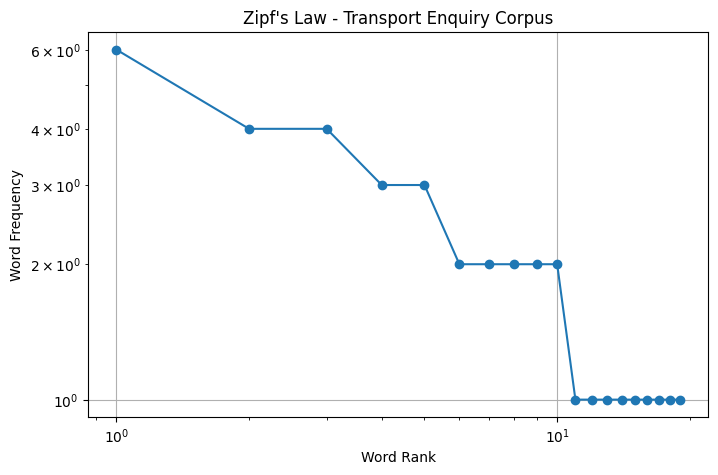


VOCABULARY AND UNK ANALYSIS
---------------------------
Threshold: 1 | Vocabulary: 19 | UNK Tokens: 0 | UNK Percentage: 0.0 %
Threshold: 2 | Vocabulary: 10 | UNK Tokens: 9 | UNK Percentage: 23.08 %
Threshold: 3 | Vocabulary: 5 | UNK Tokens: 19 | UNK Percentage: 48.72 %
Threshold: 5 | Vocabulary: 1 | UNK Tokens: 33 | UNK Percentage: 84.62 %

DEVELOPMENT SET OOV ANALYSIS
----------------------------
Development Tokens: 9
Unknown Words: ['madurai', '7:00']
OOV Count: 2
OOV Rate: 22.22 %


In [ ]:

import re
import math
from collections import Counter
import matplotlib.pyplot as plt

# Sample transport enquiry corpus
train_data = [
    "Two tickets to Vellore",
    "two tickets to Chennai",
    "Bus to Vellore at 6:30",
    "Train from Chennai to vellore",
    "Please book two tickets",
    "Book return ticket to Chennai",
    "Bus fare to Vellore is 50 rupees",
    "Train leaves Chennai at 6:30"
]

dev_data = [
    "Two tickets to Madurai",
    "Bus from Vellore at 7:00"
]


# Step 1: Tokenisation
def tokenize(text):
    # Remove common speech disfluencies
    text = re.sub(r"\b(uh|um)\b", " ", text, flags=re.IGNORECASE)

    # Keep time expressions such as 6:30 as one token
    return re.findall(
        r"\d{1,2}:\d{2}|[A-Za-z]+(?:'[A-Za-z]+)?|\d+",
        text
    )


# Step 2: Count tokens
tokens = []

for sentence in train_data:
    tokens.extend(tokenize(sentence))

# Convert to lowercase for counting types
lower_tokens = [word.lower() for word in tokens]

token_count = len(tokens)
word_types = set(lower_tokens)
type_count = len(word_types)

# Preserve original spelling and capitalisation for word forms
word_forms = set(tokens)
word_form_count = len(word_forms)


# Step 3: Find lemmas using a small demonstration dictionary
lemma_dictionary = {
    "tickets": "ticket",
    "ticket": "ticket",
    "leaves": "leave",
    "is": "be",
    "rupees": "rupee"
}

def get_lemma(word):
    word = word.lower()
    return lemma_dictionary.get(word, word)


lemmas = set(get_lemma(word) for word in lower_tokens)
lemma_count = len(lemmas)


print("WORD COUNT INFORMATION")
print("----------------------")
print("Total Tokens:", token_count)
print("Unique Types:", type_count)
print("Unique Lemmas:", lemma_count)
print("Unique Word Forms:", word_form_count)


# Step 4: Compare two tokenisation decisions
def split_time_token(text):
    text = re.sub(r"\b(uh|um)\b", " ", text, flags=re.IGNORECASE)
    return re.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?|\d+", text)


normal_vocab = set(lower_tokens)

split_tokens = []
for sentence in train_data:
    split_tokens.extend(split_time_token(sentence))

split_vocab = set(word.lower() for word in split_tokens)

print("\nTOKENISATION COMPARISON")
print("-----------------------")
print("6:30 treated as one token:", len(normal_vocab))
print("6:30 split into 6 and 30:", len(split_vocab))


# Step 5: Word frequency and Zipf's law
frequency = Counter(lower_tokens)

ranked_words = frequency.most_common()

print("\nTOP FIVE FREQUENT WORDS")
print("-----------------------")

for word, count in ranked_words[:5]:
    print(word, ":", count)

ranks = list(range(1, len(ranked_words) + 1))
frequencies = [count for word, count in ranked_words]

# Estimate the Zipf slope
log_ranks = [math.log(rank) for rank in ranks]
log_frequencies = [math.log(count) for count in frequencies]

n = len(ranks)
mean_x = sum(log_ranks) / n
mean_y = sum(log_frequencies) / n

slope = sum(
    (log_ranks[i] - mean_x) *
    (log_frequencies[i] - mean_y)
    for i in range(n)
) / sum((x - mean_x) ** 2 for x in log_ranks)

print("\nEstimated Zipf slope:", round(slope, 2))
print("Ideal Zipf slope is approximately -1.")


# Plot rank-frequency distribution
plt.figure(figsize=(8, 5))
plt.plot(ranks, frequencies, marker="o")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Word Rank")
plt.ylabel("Word Frequency")
plt.title("Zipf's Law - Transport Enquiry Corpus")
plt.grid(True)
plt.show()


# Step 6: Vocabulary with unknown-word thresholds
print("\nVOCABULARY AND UNK ANALYSIS")
print("---------------------------")

for threshold in [1, 2, 3, 5]:

    vocabulary = {
        word for word, count in frequency.items()
        if count >= threshold
    }

    unknown_tokens = sum(
        count for word, count in frequency.items()
        if count < threshold
    )

    unknown_percentage = (
        unknown_tokens / token_count
    ) * 100

    print(
        "Threshold:", threshold,
        "| Vocabulary:", len(vocabulary),
        "| UNK Tokens:", unknown_tokens,
        "| UNK Percentage:", round(unknown_percentage, 2), "%"
    )


# Step 7: Development set OOV rate
training_vocabulary = set(lower_tokens)

dev_tokens = []

for sentence in dev_data:
    dev_tokens.extend(
        word.lower() for word in tokenize(sentence)
    )

oov_words = [
    word for word in dev_tokens
    if word not in training_vocabulary
]

oov_rate = (len(oov_words) / len(dev_tokens)) * 100

print("\nDEVELOPMENT SET OOV ANALYSIS")
print("----------------------------")
print("Development Tokens:", len(dev_tokens))
print("Unknown Words:", oov_words)
print("OOV Count:", len(oov_words))
print("OOV Rate:", round(oov_rate, 2), "%")


In [ ]:

# TASK 2: UNSMOOTHED N-GRAM LANGUAGE MODELS

import random
import math
from collections import Counter

random.seed(42)

# -----------------------------------------
# 1. CREATE TRAINING AND DEVELOPMENT CORPUS
# -----------------------------------------

print("1. TRANSPORT ENQUIRY CORPUS")
print("---------------------------")

train_sentences = [
    "two tickets to vellore",
    "two tickets to chennai",
    "bus to vellore",
    "train to chennai",
    "what is the bus fare",
    "what is the train fare",
    "book a ticket to vellore",
    "book a ticket to chennai",
    "when does the bus arrive",
    "when does the train arrive",
    "return ticket to vellore",
    "return ticket to chennai"
]

dev_sentences = [
    "two tickets to vellore",
    "please book a return ticket",
    "bus fare to madurai"
]

def tokenize(sentence):
    return sentence.lower().split()

train = [tokenize(s) for s in train_sentences]
dev = [tokenize(s) for s in dev_sentences]

BOS = "<s>"
EOS = "</s>"

print("Training utterances:", len(train))
print("Development utterances:", len(dev))


# -----------------------------------------
# 2. COUNT UNIGRAMS, BIGRAMS AND TRIGRAMS
# -----------------------------------------

print("\n2. N-GRAM COUNTING")
print("------------------")

unigram_counts = Counter()
bigram_counts = Counter()
trigram_counts = Counter()

bigram_context_counts = Counter()
trigram_context_counts = Counter()

for sentence in train:

    # Unigram counting
    unigram_sequence = sentence + [EOS]
    unigram_counts.update(unigram_sequence)

    # Bigram counting
    bigram_sequence = [BOS] + sentence + [EOS]

    bigram_counts.update(
        zip(bigram_sequence[:-1], bigram_sequence[1:])
    )

    bigram_context_counts.update(bigram_sequence[:-1])

    # Trigram counting
    trigram_sequence = [BOS, BOS] + sentence + [EOS]

    trigram_counts.update(
        zip(
            trigram_sequence[:-2],
            trigram_sequence[1:-1],
            trigram_sequence[2:]
        )
    )

    trigram_context_counts.update(
        zip(trigram_sequence[:-2], trigram_sequence[1:-1])
    )

vocabulary = set(unigram_counts)
total_words = sum(unigram_counts.values())

print("Total word tokens:", total_words)
print("Vocabulary size:", len(vocabulary))

print("\nUnigram Counts:")

for word, count in unigram_counts.items():
    print(word, ":", count)

print("\nTotal Bigram Types:", len(bigram_counts))
print("Total Trigram Types:", len(trigram_counts))


# -----------------------------------------
# 3. UNIGRAM MODEL
# -----------------------------------------

print("\n3. UNIGRAM MODEL")
print("----------------")

def unigram_probability(word):

    return unigram_counts[word] / total_words


print("P(two):", round(unigram_probability("two"), 4))
print("P(bus):", round(unigram_probability("bus"), 4))
print("P(ticket):", round(unigram_probability("ticket"), 4))


# -----------------------------------------
# 4. BIGRAM MODEL
# -----------------------------------------

print("\n4. BIGRAM MODEL")
print("----------------")

def bigram_probability(previous, current):

    count = bigram_counts[(previous, current)]
    context_count = bigram_context_counts[previous]

    if context_count == 0:
        return 0

    return count / context_count


print("P(tickets | two):",
      round(bigram_probability("two", "tickets"), 4))

print("P(to | tickets):",
      round(bigram_probability("tickets", "to"), 4))

print("P(bus | the):",
      round(bigram_probability("the", "bus"), 4))


# -----------------------------------------
# 5. TRIGRAM MODEL
# -----------------------------------------

print("\n5. TRIGRAM MODEL")
print("----------------")

def trigram_probability(first, second, current):

    count = trigram_counts[(first, second, current)]

    context_count = trigram_context_counts[(first, second)]

    if context_count == 0:
        return 0

    return count / context_count


print("P(to | two, tickets):",
      round(trigram_probability("two", "tickets", "to"), 4))

print("P(vellore | tickets, to):",
      round(trigram_probability("tickets", "to", "vellore"), 4))


# -----------------------------------------
# 6. SENTENCE PROBABILITY CALCULATION
# -----------------------------------------

print("\n6. SENTENCE PROBABILITY")
print("-----------------------")

def calculate_unigram(sentence):

    sequence = sentence + [EOS]

    factors = [
        unigram_probability(word)
        for word in sequence
    ]

    return math.prod(factors), factors


def calculate_bigram(sentence):

    sequence = [BOS] + sentence + [EOS]

    factors = []

    for previous, current in zip(
        sequence[:-1], sequence[1:]
    ):

        factors.append(
            bigram_probability(previous, current)
        )

    return math.prod(factors), factors


def calculate_trigram(sentence):

    sequence = [BOS, BOS] + sentence + [EOS]

    factors = []

    for first, second, current in zip(
        sequence[:-2],
        sequence[1:-1],
        sequence[2:]
    ):

        factors.append(
            trigram_probability(first, second, current)
        )

    return math.prod(factors), factors


test_sentences = [
    "two tickets to vellore",
    "what is the bus fare",
    "two bus to chennai"
]

for text in test_sentences:

    sentence = tokenize(text)

    uni_prob, uni_factors = calculate_unigram(sentence)
    bi_prob, bi_factors = calculate_bigram(sentence)
    tri_prob, tri_factors = calculate_trigram(sentence)

    print("\nSentence:", text)

    print("Unigram factors:", uni_factors)
    print("Unigram Probability:", uni_prob)

    print("Bigram factors:", bi_factors)
    print("Bigram Probability:", bi_prob)

    print("Trigram factors:", tri_factors)
    print("Trigram Probability:", tri_prob)


# -----------------------------------------
# 7. IDENTIFY ZERO-PROBABILITY BIGRAMS
# -----------------------------------------

print("\n7. ZERO-PROBABILITY ANALYSIS")
print("----------------------------")

sentence = tokenize("two bus to chennai")

sequence = [BOS] + sentence + [EOS]

for previous, current in zip(
    sequence[:-1], sequence[1:]
):

    probability = bigram_probability(previous, current)

    if probability == 0:

        print("Unseen Bigram:", previous, "->", current)
        print("Probability:", probability)


# -----------------------------------------
# 8. MODEL SPARSITY ANALYSIS
# -----------------------------------------

print("\n8. MODEL SPARSITY ANALYSIS")
print("--------------------------")

train_bigrams = set(bigram_counts.keys())
train_trigrams = set(trigram_counts.keys())

dev_bigrams = set()
dev_trigrams = set()

for sentence in dev:

    seq2 = [BOS] + sentence + [EOS]

    dev_bigrams.update(
        zip(seq2[:-1], seq2[1:])
    )

    seq3 = [BOS, BOS] + sentence + [EOS]

    dev_trigrams.update(
        zip(seq3[:-2], seq3[1:-1], seq3[2:])
    )

V = len(vocabulary)

possible_bigrams = (V + 1) * V
possible_trigrams = (V + 1) ** 2 * V

bigram_sparsity = (
    len(train_bigrams) / possible_bigrams
) * 100

trigram_sparsity = (
    len(train_trigrams) / possible_trigrams
) * 100

unseen_dev_bigrams = dev_bigrams - train_bigrams
unseen_dev_trigrams = dev_trigrams - train_trigrams

bigram_unseen_rate = (
    len(unseen_dev_bigrams) / len(dev_bigrams)
) * 100

trigram_unseen_rate = (
    len(unseen_dev_trigrams) / len(dev_trigrams)
) * 100

print("Possible Bigrams:", possible_bigrams)
print("Observed Bigrams:", len(train_bigrams))
print("Bigram Coverage:", round(bigram_sparsity, 2), "%")

print("\nPossible Trigrams:", possible_trigrams)
print("Observed Trigrams:", len(train_trigrams))
print("Trigram Coverage:", round(trigram_sparsity, 2), "%")

print("\nUnseen Development Bigrams:",
      len(unseen_dev_bigrams), "/", len(dev_bigrams))

print("Unseen Development Bigram Rate:",
      round(bigram_unseen_rate, 2), "%")

print("\nUnseen Development Trigrams:",
      len(unseen_dev_trigrams), "/", len(dev_trigrams))

print("Unseen Development Trigram Rate:",
      round(trigram_unseen_rate, 2), "%")


# -----------------------------------------
# 9. GENERATE SENTENCES FROM N-GRAM MODELS
# -----------------------------------------

print("\n9. SENTENCE GENERATION")
print("----------------------")

def generate_unigram():

    words = []

    for _ in range(12):

        word = random.choices(
            list(unigram_counts.keys()),
            weights=list(unigram_counts.values())
        )[0]

        if word == EOS:
            break

        words.append(word)

    return " ".join(words) if words else "(empty)"


def generate_bigram():

    words = []
    previous = BOS

    for _ in range(12):

        candidates = [
            word for (context, word) in bigram_counts
            if context == previous
        ]

        if not candidates:
            break

        weights = [
            bigram_counts[(previous, word)]
            for word in candidates
        ]

        word = random.choices(
            candidates, weights=weights
        )[0]

        if word == EOS:
            break

        words.append(word)
        previous = word

    return " ".join(words) if words else "(empty)"


def generate_trigram():

    words = []
    first = BOS
    second = BOS

    for _ in range(12):

        candidates = [
            current
            for (a, b, current) in trigram_counts
            if a == first and b == second
        ]

        if not candidates:
            break

        weights = [
            trigram_counts[(first, second, word)]
            for word in candidates
        ]

        word = random.choices(
            candidates, weights=weights
        )[0]

        if word == EOS:
            break

        words.append(word)

        first, second = second, word

    return " ".join(words) if words else "(empty)"


print("\nUnigram Generated Sentences:")

for i in range(10):
    print(i + 1, ".", generate_unigram())


print("\nBigram Generated Sentences:")

for i in range(10):
    print(i + 1, ".", generate_bigram())


print("\nTrigram Generated Sentences:")

for i in range(10):
    print(i + 1, ".", generate_trigram())


# -----------------------------------------
# 10. FINAL SUMMARY
# -----------------------------------------

print("\n10. FINAL SUMMARY")
print("-----------------")

print("Unigram, Bigram and Trigram models created.")
print("Maximum Likelihood probabilities calculated.")
print("Sentence probabilities calculated.")
print("Zero-probability bigrams identified.")
print("Model sparsity measured.")
print("30 sample utterances generated.")


1. TRANSPORT ENQUIRY CORPUS
---------------------------
Training utterances: 12
Development utterances: 3

2. N-GRAM COUNTING
------------------
Total word tokens: 64
Vocabulary size: 19

Unigram Counts:
two : 2
tickets : 2
to : 8
vellore : 4
</s> : 12
chennai : 4
bus : 3
train : 3
what : 2
is : 2
the : 4
fare : 2
book : 2
a : 2
ticket : 4
when : 2
does : 2
arrive : 2
return : 2

Total Bigram Types: 31
Total Trigram Types: 40

3. UNIGRAM MODEL
----------------
P(two): 0.0312
P(bus): 0.0469
P(ticket): 0.0625

4. BIGRAM MODEL
----------------
P(tickets | two): 1.0
P(to | tickets): 1.0
P(bus | the): 0.5

5. TRIGRAM MODEL
----------------
P(to | two, tickets): 1.0
P(vellore | tickets, to): 0.5

6. SENTENCE PROBABILITY
-----------------------

Sentence: two tickets to vellore
Unigram factors: [0.03125, 0.03125, 0.125, 0.0625, 0.1875]
Unigram Probability: 1.430511474609375e-06
Bigram factors: [0.16666666666666666, 1.0, 1.0, 0.5, 1.0]
Bigram Probability: 0.08333333333333333
Trigram factors: [

In [ ]:

import re
import math
from collections import Counter, defaultdict

# -----------------------------------------
# 1. Training and development data
# -----------------------------------------

train_sentences = [
    "i want bus timings",
    "show me bus routes",
    "what is the bus fare",
    "i need two tickets",
    "book two tickets to vellore",
    "when is the next bus",
    "show train timings",
    "i want to cancel ticket",
    "how much is the ticket fare",
    "bus from chennai to vellore",
    "train from chennai to madurai",
    "i need refund for ticket"
]

dev_sentences = [
    "i want two tickets",
    "show me train timings",
    "bus to madurai"
]

def tokenize(sentence):
    return re.findall(r"\b\w+\b", sentence.lower())

train_tokens = [tokenize(s) for s in train_sentences]
dev_tokens = [tokenize(s) for s in dev_sentences]

# Add sentence boundary markers
train_tokens = [["<s>"] + s + ["</s>"] for s in train_tokens]
dev_tokens = [["<s>"] + s + ["</s>"] for s in dev_tokens]

# -----------------------------------------
# 2. Build bigram counts
# -----------------------------------------

bigram_counts = Counter()
context_counts = Counter()
vocabulary = set()

for sentence in train_tokens:
    vocabulary.update(sentence)

    for i in range(len(sentence) - 1):
        bigram = (sentence[i], sentence[i + 1])
        bigram_counts[bigram] += 1
        context_counts[sentence[i]] += 1

V = len(vocabulary)
total_bigrams = sum(bigram_counts.values())
possible_bigrams = V * V
unseen_bigrams = possible_bigrams - len(bigram_counts)

print("VOCABULARY SIZE:", V)
print("TOTAL BIGRAM TOKENS:", total_bigrams)
print("OBSERVED BIGRAM TYPES:", len(bigram_counts))
print("UNSEEN BIGRAM TYPES:", unseen_bigrams)

# -----------------------------------------
# 3. Add-one and Add-k smoothing
# -----------------------------------------

def add_k_probability(word1, word2, k):
    count = bigram_counts[(word1, word2)]
    context = context_counts[word1]

    return (count + k) / (context + k * V)

# -----------------------------------------
# 4. Display smoothing table for one context
# -----------------------------------------

context_word = "to"
context_total = context_counts[context_word]

print("\nADD-ONE AND ADD-K TABLE")
print("Context:", context_word)
print("Original context count:", context_total)

print("\nNext Word | Original Count | Add-one Probability | Add-k Probability")

for word in sorted(vocabulary):
    count = bigram_counts[(context_word, word)]

    p_one = add_k_probability(context_word, word, 1)
    p_k = add_k_probability(context_word, word, 0.1)

    if count > 0:
        print(word, "|", count, "|",
              round(p_one, 4), "|", round(p_k, 4))

# Calculate how much probability mass is removed
# from the observed bigrams and assigned to unseen ones.

for k in [1, 0.1]:
    removed_mass = (k * V) / (context_total + k * V)
    retained_mass = context_total / (context_total + k * V)

    print("\nFor k =", k)
    print("Mass retained by observed bigrams:",
          round(retained_mass, 4))
    print("Mass assigned to unseen bigrams:",
          round(removed_mass, 4))

# Effective discounted counts for observed bigrams
print("\nEFFECTIVE COUNTS USING ADD-ONE")

for (w1, w2), count in bigram_counts.items():
    if w1 == context_word:
        probability = add_k_probability(w1, w2, 1)
        effective_count = probability * context_total

        print(w1, "->", w2,
              "Original:", count,
              "Effective:", round(effective_count, 4))

# -----------------------------------------
# 5. Good-Turing discounting
# -----------------------------------------

# Frequency of frequencies: Nr
frequency_of_frequencies = Counter(bigram_counts.values())

print("\nGOOD-TURING FREQUENCY TABLE")
print("Frequency r | Number of bigrams Nr")

for r in sorted(frequency_of_frequencies):
    print(r, "|", frequency_of_frequencies[r])

# Calculate Good-Turing revised counts
def good_turing_count(count):
    Nr = frequency_of_frequencies.get(count, 0)
    Nr_next = frequency_of_frequencies.get(count + 1, 0)

    if Nr > 0 and Nr_next > 0:
        return (count + 1) * Nr_next / Nr

    # High-frequency tail fallback
    return count

print("\nGOOD-TURING REVISED COUNTS")

for bigram, count in bigram_counts.items():
    revised = good_turing_count(count)

    print(bigram, "Original:", count,
          "Revised:", round(revised, 4))

# Probability mass assigned to unseen bigram types
N1 = frequency_of_frequencies.get(1, 0)

if unseen_bigrams > 0:
    p0 = N1 / total_bigrams
    probability_per_unseen = p0 / unseen_bigrams
else:
    p0 = 0
    probability_per_unseen = 0

# Calculate revised counts for seen bigrams
revised_counts = {
    bigram: good_turing_count(count)
    for bigram, count in bigram_counts.items()
}

revised_total = sum(revised_counts.values())

# Normalise seen probabilities to the remaining probability mass
seen_mass = 1 - p0

good_turing_probabilities = {}

for bigram, revised in revised_counts.items():
    if revised_total > 0:
        good_turing_probabilities[bigram] = (
            seen_mass * revised / revised_total
        )

print("\nGOOD-TURING UNSEEN PROBABILITY MASS:", round(p0, 6))
print("PROBABILITY OF EACH UNSEEN BIGRAM:",
      round(probability_per_unseen, 8))

# -----------------------------------------
# 6. Perplexity calculation
# -----------------------------------------

def evaluate_add_k(sentences, k):
    log_probability = 0
    total_words = 0

    for sentence in sentences:
        for i in range(len(sentence) - 1):
            w1, w2 = sentence[i], sentence[i + 1]

            p = add_k_probability(w1, w2, k)

            log_probability += math.log(p)
            total_words += 1

    return math.exp(-log_probability / total_words)

def evaluate_good_turing(sentences):
    log_probability = 0
    total_words = 0

    for sentence in sentences:
        for i in range(len(sentence) - 1):
            bigram = (sentence[i], sentence[i + 1])

            if bigram in good_turing_probabilities:
                p = good_turing_probabilities[bigram]
            else:
                p = probability_per_unseen

            if p <= 0:
                return float("inf")

            log_probability += math.log(p)
            total_words += 1

    return math.exp(-log_probability / total_words)

print("\nDEVELOPMENT SET PERPLEXITY")

print("Add-one:",
      round(evaluate_add_k(dev_tokens, 1), 4))

print("Add-k (k=0.1):",
      round(evaluate_add_k(dev_tokens, 0.1), 4))

print("Good-Turing:",
      round(evaluate_good_turing(dev_tokens), 4))

# -----------------------------------------
# 7. Test an unseen bigram
# -----------------------------------------

test_bigram = ("two", "bus")

print("\nUNSEEN BIGRAM TEST:", test_bigram)

print("Original count:",
      bigram_counts[test_bigram])

print("Add-one probability:",
      round(add_k_probability(test_bigram[0],
                              test_bigram[1], 1), 6))

print("Add-k probability:",
      round(add_k_probability(test_bigram[0],
                              test_bigram[1], 0.1), 6))

print("Good-Turing probability:",
      round(probability_per_unseen, 8))


VOCABULARY SIZE: 31
TOTAL BIGRAM TOKENS: 68
OBSERVED BIGRAM TYPES: 52
UNSEEN BIGRAM TYPES: 909

ADD-ONE AND ADD-K TABLE
Context: to
Original context count: 4

Next Word | Original Count | Add-one Probability | Add-k Probability
cancel | 1 | 0.0571 | 0.1549
madurai | 1 | 0.0571 | 0.1549
vellore | 2 | 0.0857 | 0.2958

For k = 1
Mass retained by observed bigrams: 0.1143
Mass assigned to unseen bigrams: 0.8857

For k = 0.1
Mass retained by observed bigrams: 0.5634
Mass assigned to unseen bigrams: 0.4366

EFFECTIVE COUNTS USING ADD-ONE
to -> vellore Original: 2 Effective: 0.3429
to -> cancel Original: 1 Effective: 0.2286
to -> madurai Original: 1 Effective: 0.2286

GOOD-TURING FREQUENCY TABLE
Frequency r | Number of bigrams Nr
1 | 39
2 | 11
3 | 1
4 | 1

GOOD-TURING REVISED COUNTS
('<s>', 'i') Original: 4 Revised: 4
('i', 'want') Original: 2 Revised: 0.2727
('want', 'bus') Original: 1 Revised: 0.5641
('bus', 'timings') Original: 1 Revised: 0.5641
('timings', '</s>') Original: 2 Revised: 0.27

In [ ]:

import re
import math
from collections import Counter, defaultdict

# 1. Training and development corpus

train_sentences = [
    "i want bus timings",
    "show me bus routes",
    "what is the bus fare",
    "i need two tickets",
    "book two tickets to vellore",
    "when is the next bus",
    "show train timings",
    "i want to cancel ticket",
    "how much is the ticket fare",
    "bus from chennai to vellore",
    "train from chennai to madurai",
    "i need refund for ticket"
]

dev_sentences = [
    "i want two tickets",
    "show me train timings",
    "bus to madurai"
]

def tokenize(sentence):
    return re.findall(r"\b\w+\b", sentence.lower())

train = [["<s>"] + tokenize(s) + ["</s>"]
         for s in train_sentences]

dev = [["<s>"] + tokenize(s) + ["</s>"]
       for s in dev_sentences]

# 2. Build unigram, bigram and trigram counts

unigrams = Counter()
bigrams = Counter()
trigrams = Counter()

for sentence in train:
    unigrams.update(sentence)

    for i in range(len(sentence) - 1):
        bigrams[(sentence[i], sentence[i+1])] += 1

    for i in range(len(sentence) - 2):
        trigrams[(sentence[i], sentence[i+1],
                  sentence[i+2])] += 1

vocabulary = set(unigrams)
V = len(vocabulary)
total_words = sum(unigrams.values())

print("VOCABULARY SIZE:", V)
print("UNIGRAM TYPES:", len(unigrams))
print("BIGRAM TYPES:", len(bigrams))
print("TRIGRAM TYPES:", len(trigrams))

# 3. Basic probability functions

def unigram_probability(word):
    return (unigrams[word] + 0.1) / (
        total_words + 0.1 * V
    )

def bigram_probability(w1, w2):
    return (bigrams[(w1, w2)] + 0.1) / (
        unigrams[w1] + 0.1 * V
    )

# 4. Good-Turing discounting for trigrams

frequency_of_frequencies = Counter(trigrams.values())

def gt_discount(count):
    Nr = frequency_of_frequencies.get(count, 0)
    Nr_next = frequency_of_frequencies.get(count + 1, 0)

    if Nr > 0 and Nr_next > 0:
        revised = (count + 1) * Nr_next / Nr

        # Keep the discounted count no greater
        # than the original count.
        return min(count, revised)

    # High-frequency tail fallback
    return count

# 5. Katz backoff model

# Store all observed next words for each two-word context.
continuations = defaultdict(set)

for w1, w2, w3 in trigrams:
    continuations[(w1, w2)].add(w3)

def katz_alpha(w1, w2):
    context_count = bigrams[(w1, w2)]

    if context_count == 0:
        return 1.0

    seen_words = continuations[(w1, w2)]

    # Probability mass retained by observed trigrams
    seen_mass = sum(
        gt_discount(trigrams[(w1, w2, w3)])
        / context_count
        for w3 in seen_words
    )

    # Lower-order probability mass already assigned
    # to the seen trigram continuations
    lower_seen_mass = sum(
        bigram_probability(w2, w3)
        for w3 in seen_words
    )

    remaining_mass = 1 - seen_mass
    lower_unseen_mass = 1 - lower_seen_mass

    if lower_unseen_mass <= 0:
        return 1.0

    return max(0, remaining_mass) / lower_unseen_mass

def katz_probability(w1, w2, w3):
    count = trigrams[(w1, w2, w3)]
    context_count = bigrams[(w1, w2)]

    # Use discounted trigram probability if observed
    if count > 0 and context_count > 0:
        return gt_discount(count) / context_count

    # Back off to the bigram model
    if context_count > 0:
        alpha = katz_alpha(w1, w2)
        return alpha * bigram_probability(w2, w3)

    # If the trigram context is unseen, use bigram
    return bigram_probability(w2, w3)

# 6. Stupid Backoff

def stupid_backoff_score(w1, w2, w3):
    if trigrams[(w1, w2, w3)] > 0:
        return trigrams[(w1, w2, w3)] / bigrams[(w1, w2)]

    elif bigrams[(w2, w3)] > 0:
        return 0.4 * (
            bigrams[(w2, w3)] / unigrams[w2]
        )

    else:
        return 0.4 * 0.4 * unigram_probability(w3)

# 7. Linear interpolation

def linear_interpolation(w1, w2, w3, lambdas):
    l1, l2, l3 = lambdas

    p1 = unigram_probability(w3)
    p2 = bigram_probability(w2, w3)

    context_count = bigrams[(w1, w2)]

    if context_count > 0:
        p3 = trigrams[(w1, w2, w3)] / context_count
    else:
        p3 = 0

    return l1*p1 + l2*p2 + l3*p3

# 8. Deleted interpolation

# Estimate lambda weights by leaving out one
# occurrence at a time and checking which
# probability order predicts it best.

wins = [0, 0, 0]

band_wins = {
    "Low (1)": [0, 0, 0],
    "Medium (2-3)": [0, 0, 0],
    "High (4+)": [0, 0, 0]
}

for (w1, w2, w3), count in trigrams.items():

    for _ in range(count):

        # Leave-one-out estimates
        c3 = trigrams[(w1, w2, w3)] - 1
        c2 = bigrams[(w1, w2)] - 1
        c1 = unigrams[w2] - 1
        cw = unigrams[w3] - 1

        scores = []

        # Trigram estimate
        p3 = c3 / c2 if c2 > 0 else -1

        # Bigram estimate
        p2 = bigrams[(w2, w3)] / c1 if c1 > 0 else -1

        # Unigram estimate
        p1 = cw / (total_words - 1) if total_words > 1 else 0

        scores = [p1, p2, p3]

        best = max(range(3), key=lambda i: scores[i])

        wins[best] += 1

        # Group contexts by their original count
        original_context_count = bigrams[(w1, w2)]

        if original_context_count == 1:
            band = "Low (1)"
        elif original_context_count <= 3:
            band = "Medium (2-3)"
        else:
            band = "High (4+)"

        band_wins[band][best] += 1

total_wins = sum(wins)

if total_wins > 0:
    deleted_lambdas = [
        x / total_wins for x in wins
    ]
else:
    deleted_lambdas = [0.33, 0.33, 0.34]

print("\nDELETED INTERPOLATION WEIGHTS")
print("Unigram:", round(deleted_lambdas[0], 4))
print("Bigram:", round(deleted_lambdas[1], 4))
print("Trigram:", round(deleted_lambdas[2], 4))

print("\nWEIGHTS BY CONTEXT COUNT BAND")

for band, values in band_wins.items():
    total = sum(values)

    if total > 0:
        weights = [round(x/total, 4) for x in values]
    else:
        weights = [0, 0, 0]

    print(band, ":", weights)

# -----------------------------------------
# 9. Perplexity evaluation
# -----------------------------------------

def calculate_perplexity(model_function, sentences):
    log_sum = 0
    total = 0

    for sentence in sentences:
        for i in range(2, len(sentence)):
            w1, w2, w3 = sentence[i-2:i+1]

            p = model_function(w1, w2, w3)

            if p <= 0:
                return float("inf")

            log_sum += math.log(p)
            total += 1

    return math.exp(-log_sum / total)

# Fixed interpolation weights
fixed_lambdas = [0.2, 0.3, 0.5]

def fixed_interpolation(w1, w2, w3):
    return linear_interpolation(
        w1, w2, w3, fixed_lambdas
    )

def deleted_interpolation_model(w1, w2, w3):
    return linear_interpolation(
        w1, w2, w3, deleted_lambdas
    )

print("\nDEVELOPMENT SET PERPLEXITY")

print("Katz Backoff:",
      round(calculate_perplexity(
          katz_probability, dev), 4))

print("Fixed Linear Interpolation:",
      round(calculate_perplexity(
          fixed_interpolation, dev), 4))

print("Deleted Interpolation:",
      round(calculate_perplexity(
          deleted_interpolation_model, dev), 4))

# -----------------------------------------
# 10. Compare an unseen trigram
# -----------------------------------------

test = ("i", "want", "tickets")

print("\nUNSEEN TRIGRAM TEST:", test)
print("Trigram count:", trigrams[test])

print("Katz probability:",
      round(katz_probability(*test), 8))

print("Fixed interpolation probability:",
      round(fixed_interpolation(*test), 8))

print("Deleted interpolation probability:",
      round(deleted_interpolation_model(*test), 8))

print("Stupid Backoff score:",
      round(stupid_backoff_score(*test), 8))

print("\nNOTE: Stupid Backoff produces scores,")
print("not normalized probabilities or true perplexity.")


VOCABULARY SIZE: 31
UNIGRAM TYPES: 31
BIGRAM TYPES: 52
TRIGRAM TYPES: 52

DELETED INTERPOLATION WEIGHTS
Unigram: 0.2143
Bigram: 0.7857
Trigram: 0.0

WEIGHTS BY CONTEXT COUNT BAND
Low (1) : [0.3429, 0.6571, 0.0]
Medium (2-3) : [0.0, 1.0, 0.0]
High (4+) : [0.0, 1.0, 0.0]

DEVELOPMENT SET PERPLEXITY
Katz Backoff: 9.7913
Fixed Linear Interpolation: 9.83
Deleted Interpolation: 8.601

UNSEEN TRIGRAM TEST: ('i', 'want', 'tickets')
Trigram count: 0
Katz probability: 0.02873563
Fixed interpolation probability: 0.0109365
Deleted interpolation probability: 0.02082132
Stupid Backoff score: 0.00404332

NOTE: Stupid Backoff produces scores,
not normalized probabilities or true perplexity.


In [ ]:

import math
import random
from collections import Counter

random.seed(42)

# -----------------------------------------
# 1. TRAINING AND DEVELOPMENT DATA
# -----------------------------------------

train = [
    "i want two tickets to vellore",
    "i need a bus to chennai",
    "when is the next bus to vellore",
    "book two tickets to chennai",
    "what is the fare to madurai",
    "i want to know the train timing",
    "when does the bus leave",
    "is there a train to vellore",
    "i need one ticket to madurai",
    "tell me the bus fare",
    "what time is the next train",
    "i want to book a return ticket"
]

dev = [
    "i want tickets to vellore",
    "when is the bus to madurai",
    "i need two tickets to chennai"
]

# Add sentence boundary markers
train = [["<s>"] + s.lower().split() + ["</s>"] for s in train]
dev = [["<s>"] + s.lower().split() + ["</s>"] for s in dev]

# Build vocabulary
vocab = set()
for sentence in train:
    vocab.update(sentence)

V = len(vocab)
total_words = sum(len(s) - 1 for s in train)

print("VOCABULARY SIZE:", V)
print("TRAINING WORD TOKENS:", total_words)

# -----------------------------------------
# 2. COUNT UNIGRAMS, BIGRAMS AND TRIGRAMS
# -----------------------------------------

uni = Counter()
bi = Counter()
tri = Counter()
context_bi = Counter()
context_tri = Counter()

for sentence in train:
    for i in range(1, len(sentence)):
        uni[sentence[i]] += 1
        bi[(sentence[i-1], sentence[i])] += 1
        context_bi[sentence[i-1]] += 1

    for i in range(2, len(sentence)):
        tri[tuple(sentence[i-2:i+1])] += 1
        context_tri[tuple(sentence[i-2:i])] += 1

# -----------------------------------------
# 3. PROBABILITY FUNCTIONS
# -----------------------------------------

def unigram_prob(word):
    return uni[word] / total_words

def bigram_mle(w1, w2):
    if context_bi[w1] == 0:
        return 0
    return bi[(w1, w2)] / context_bi[w1]

def trigram_mle(w1, w2, w3):
    if context_tri[(w1, w2)] == 0:
        return 0
    return tri[(w1, w2, w3)] / context_tri[(w1, w2)]

def bigram_add_k(w1, w2, k=0.1):
    return (bi[(w1, w2)] + k) / (
        context_bi[w1] + k * V
    )

def trigram_add_k(w1, w2, w3, k=0.1):
    return (tri[(w1, w2, w3)] + k) / (
        context_tri[(w1, w2)] + k * V
    )

def add_one_bigram(w1, w2):
    return bigram_add_k(w1, w2, 1)

# Linear interpolation
def interpolation_prob(w1, w2, w3):
    p1 = unigram_prob(w3)
    p2 = bigram_add_k(w2, w3, 0.1)
    p3 = trigram_add_k(w1, w2, w3, 0.1)

    return 0.2*p1 + 0.3*p2 + 0.5*p3

# Simplified Katz-style backoff:
# Use trigram if observed; otherwise use bigram.
def katz_style_prob(w1, w2, w3):
    if tri[(w1, w2, w3)] > 0:
        return trigram_add_k(w1, w2, w3, 0.1)
    return bigram_add_k(w2, w3, 0.1)

# -----------------------------------------
# 4. DELETED INTERPOLATION WEIGHTS
# -----------------------------------------

# Estimate interpolation weights using leave-one-out counts.
# Each training trigram occurrence votes for the highest
# leave-one-out probability among unigram, bigram and trigram.

votes = [0, 0, 0]

for sentence in train:
    for i in range(2, len(sentence)):
        w1, w2, w3 = sentence[i-2:i+1]

        c3 = tri[(w1, w2, w3)] - 1
        c2 = bi[(w2, w3)] - 1
        c1 = uni[w3] - 1

        p3 = c3 / max(context_tri[(w1, w2)] - 1, 1)
        p2 = c2 / max(context_bi[w2] - 1, 1)
        p1 = c1 / max(total_words - 1, 1)

        best = max(range(3), key=lambda x: [p1, p2, p3][x])
        votes[best] += 1

vote_total = sum(votes)
deleted_lambdas = [v / vote_total for v in votes]

def deleted_interpolation_prob(w1, w2, w3):
    p1 = unigram_prob(w3)
    p2 = bigram_add_k(w2, w3, 0.1)
    p3 = trigram_add_k(w1, w2, w3, 0.1)

    l1, l2, l3 = deleted_lambdas
    return l1*p1 + l2*p2 + l3*p3

# -----------------------------------------
# 5. CROSS-ENTROPY AND PERPLEXITY
# -----------------------------------------

def evaluate(model, data):
    total_log = 0
    word_count = 0
    utterance_log = []

    for sentence in data:
        sentence_log = 0

        for i in range(1, len(sentence)):
            if model == "Unigram MLE":
                p = unigram_prob(sentence[i])

            elif model == "Bigram MLE":
                p = bigram_mle(sentence[i-1], sentence[i])

            elif model == "Trigram MLE":
                if i >= 2:
                    p = trigram_mle(
                        sentence[i-2], sentence[i-1], sentence[i]
                    )
                else:
                    p = bigram_mle(sentence[i-1], sentence[i])

            elif model == "Add-one Bigram":
                p = add_one_bigram(sentence[i-1], sentence[i])

            elif model == "Add-k Bigram":
                p = bigram_add_k(sentence[i-1], sentence[i], 0.1)

            elif model == "Katz-style Backoff":
                if i >= 2:
                    p = katz_style_prob(
                        sentence[i-2], sentence[i-1], sentence[i]
                    )
                else:
                    p = bigram_add_k(sentence[i-1], sentence[i], 0.1)

            elif model == "Linear Interpolation":
                if i >= 2:
                    p = interpolation_prob(
                        sentence[i-2], sentence[i-1], sentence[i]
                    )
                else:
                    p = bigram_add_k(sentence[i-1], sentence[i], 0.1)

            elif model == "Deleted Interpolation":
                if i >= 2:
                    p = deleted_interpolation_prob(
                        sentence[i-2], sentence[i-1], sentence[i]
                    )
                else:
                    p = bigram_add_k(sentence[i-1], sentence[i], 0.1)

            # Zero probability makes cross-entropy infinite
            if p <= 0:
                return float("inf"), float("inf"), float("inf")

            sentence_log += -math.log2(p)
            word_count += 1

        total_log += sentence_log
        utterance_log.append(sentence_log)

    cross_entropy = total_log / word_count
    perplexity = 2 ** cross_entropy
    avg_bits_per_utterance = total_log / len(data)

    return cross_entropy, perplexity, avg_bits_per_utterance

models = [
    "Unigram MLE",
    "Bigram MLE",
    "Trigram MLE",
    "Add-one Bigram",
    "Add-k Bigram",
    "Katz-style Backoff",
    "Linear Interpolation",
    "Deleted Interpolation"
]

print("\nMODEL COMPARISON")
print("-" * 85)
print("{:<25} {:>15} {:>15} {:>20}".format(
    "Model", "Bits/word", "Perplexity", "Bits/utterance"
))

for model in models:
    ce, pp, utterance_bits = evaluate(model, dev)

    print("{:<25} {:>15} {:>15} {:>20}".format(
        model,
        round(ce, 4) if math.isfinite(ce) else "Infinity",
        round(pp, 4) if math.isfinite(pp) else "Infinity",
        round(utterance_bits, 4) if math.isfinite(utterance_bits) else "Infinity"
    ))

# -----------------------------------------
# 6. ENTROPY OF THREE DISTRIBUTIONS
# -----------------------------------------

def entropy(probabilities):
    return -sum(
        p * math.log2(p)
        for p in probabilities if p > 0
    )

# Nearly uniform distribution
nearly_uniform = [0.26, 0.25, 0.25, 0.24]

# Sharply peaked distribution
sharply_peaked = [0.90, 0.04, 0.03, 0.03]

# Distribution from the unigram model
unigram_distribution = [
    count / total_words for count in uni.values()
]

print("\nENTROPY CALCULATIONS")
print("Nearly uniform entropy:",
      round(entropy(nearly_uniform), 4), "bits")

print("Sharply peaked entropy:",
      round(entropy(sharply_peaked), 4), "bits")

print("Training unigram entropy:",
      round(entropy(unigram_distribution), 4), "bits")

# -----------------------------------------
# 7. VOCABULARY FAIRNESS DEMONSTRATION
# -----------------------------------------

# Same probability mass spread over different vocabulary sizes
prob_small_vocab = 1 / 5
prob_large_vocab = 1 / 10

print("\nVOCABULARY FAIRNESS")
print("Probability with 5 equally likely words:", prob_small_vocab)
print("Probability with 10 equally likely words:", prob_large_vocab)
print("Their perplexities are 5 and 10 respectively.")

# -----------------------------------------
# 8. SIMPLE RECOGNISER HYPOTHESIS RESCORING
# -----------------------------------------

# Demo only: replace these with the required 200 real
# recogniser hypothesis sets and their reference transcripts.

hypothesis_sets = [
    {
        "reference": "two tickets to vellore",
        "hypotheses": [
            "two tickets to vellore",
            "to tickets to vellore",
            "two tickets to velore"
        ]
    },
    {
        "reference": "i need a bus to chennai",
        "hypotheses": [
            "i need a bus to chennai",
            "i need bus to chennai",
            "i want a train to chennai"
        ]
    }
]

def score_sentence(sentence):
    words = ["<s>"] + sentence.lower().split() + ["</s>"]
    score = 0

    for i in range(1, len(words)):
        p = bigram_add_k(words[i-1], words[i], 0.1)
        score += math.log(p)

    return score

def edit_distance(a, b):
    dp = [[0] * (len(b)+1) for _ in range(len(a)+1)]

    for i in range(len(a)+1):
        dp[i][0] = i
    for j in range(len(b)+1):
        dp[0][j] = j

    for i in range(1, len(a)+1):
        for j in range(1, len(b)+1):
            cost = 0 if a[i-1] == b[j-1] else 1
            dp[i][j] = min(
                dp[i-1][j] + 1,
                dp[i][j-1] + 1,
                dp[i-1][j-1] + cost
            )

    return dp[-1][-1]

def wer(reference, hypothesis):
    ref = reference.split()
    hyp = hypothesis.split()
    return edit_distance(ref, hyp) / max(len(ref), 1)

before_errors = 0
before_words = 0
after_errors = 0
after_words = 0

print("\nRECOGNISER RESCORING")

for item in hypothesis_sets:
    reference = item["reference"]
    hypotheses = item["hypotheses"]

    # First hypothesis represents the recogniser's original choice
    original = hypotheses[0]

    # Select the hypothesis with the highest language-model score
    rescored = max(hypotheses, key=score_sentence)

    before_errors += edit_distance(reference.split(), original.split())
    before_words += len(reference.split())

    after_errors += edit_distance(reference.split(), rescored.split())
    after_words += len(reference.split())

    print("\nReference:", reference)
    print("Original choice:", original)
    print("Rescored choice:", rescored)

print("\nWER BEFORE RESCORING:",
      round(before_errors / before_words * 100, 2), "%")

print("WER AFTER RESCORING:",
      round(after_errors / after_words * 100, 2), "%")

print("\nPROGRAM COMPLETED")


VOCABULARY SIZE: 32
TRAINING WORD TOKENS: 84

MODEL COMPARISON
-------------------------------------------------------------------------------------
Model                           Bits/word      Perplexity       Bits/utterance
Unigram MLE                        4.3091         19.8236              28.7276
Bigram MLE                       Infinity        Infinity             Infinity
Trigram MLE                      Infinity        Infinity             Infinity
Add-one Bigram                     3.6362         12.4338              24.2413
Add-k Bigram                       2.1495          4.4367              14.3298
Katz-style Backoff                 2.1837          4.5431              14.5579
Linear Interpolation               2.6289          6.1853              17.5257
Deleted Interpolation                2.73          6.6345              18.1999

ENTROPY CALCULATIONS
Nearly uniform entropy: 1.9994 bits
Sharply peaked entropy: 0.6261 bits
Training unigram entropy: 4.5389 bits

VOCABUL

In [ ]:

from collections import Counter

# ---------------------------------------
# 1. DESIGN A 24-TAG POS TAGSET
# ---------------------------------------

tagset = {
    "NN": "Singular noun",
    "NNS": "Plural noun",
    "NNP": "Proper noun / station name",
    "VB": "Base verb",
    "VBD": "Past tense verb",
    "VBG": "Verb ending in -ing",
    "VBN": "Past participle",
    "VBZ": "Third-person singular verb",
    "VBP": "Present verb",
    "JJ": "Adjective",
    "RB": "Adverb",
    "PRP": "Personal pronoun",
    "PRP$": "Possessive pronoun",
    "DT": "Determiner",
    "IN": "Preposition",
    "CC": "Conjunction",
    "MD": "Modal verb",
    "TO": "Infinitive marker",
    "CD": "Cardinal number",
    "RP": "Particle",
    "UH": "Interjection",
    "WRB": "Wh-adverb",
    "WP": "Wh-pronoun",
    "WDT": "Wh-determiner"
}

penn_mapping = {tag: tag for tag in tagset}

print("NUMBER OF TAGS:", len(tagset))
print("\nTAGSET AND PENN TREEBANK MAPPING")

for tag, meaning in tagset.items():
    print(tag, "-", meaning,
          "-> Penn Treebank:", penn_mapping[tag])

# ---------------------------------------
# 2. HAND-ANNOTATED SAMPLE DATA
# ---------------------------------------

# Each item contains (word, correct_tag)

annotated_data = [
    [("i", "PRP"), ("want", "VBP"),
     ("two", "CD"), ("tickets", "NNS"),
     ("to", "IN"), ("vellore", "NNP")],

    [("book", "VB"), ("a", "DT"),
     ("ticket", "NN"), ("to", "IN"),
     ("chennai", "NNP")],

    [("the", "DT"), ("bus", "NN"),
     ("leaves", "VBZ"), ("tomorrow", "RB")],

    [("when", "WRB"), ("does", "VBZ"),
     ("the", "DT"), ("train", "NN"),
     ("arrive", "VB")],

    [("i", "PRP"), ("need", "VBP"),
     ("one", "CD"), ("return", "JJ"),
     ("ticket", "NN")],

    [("is", "VBZ"), ("there", "RB"),
     ("a", "DT"), ("train", "NN"),
     ("from", "IN"), ("madurai", "NNP")],

    [("please", "UH"), ("cancel", "VB"),
     ("my", "PRP$"), ("booking", "NN")],

    [("we", "PRP"), ("are", "VBP"),
     ("waiting", "VBG"), ("at", "IN"),
     ("the", "DT"), ("bus", "NN"),
     ("stand", "NN")],

    [("can", "MD"), ("you", "PRP"),
     ("check", "VB"), ("the", "DT"),
     ("fare", "NN")],

    [("which", "WDT"), ("bus", "NN"),
     ("goes", "VBZ"), ("to", "IN"),
     ("vellore", "NNP")],

    [("what", "WP"), ("is", "VBZ"),
     ("the", "DT"), ("next", "JJ"),
     ("train", "NN")],

    [("i", "PRP"), ("travelled", "VBD"),
     ("from", "IN"), ("chennai", "NNP"),
     ("yesterday", "RB")],

    [("the", "DT"), ("tickets", "NNS"),
     ("are", "VBP"), ("available", "JJ")],

    [("they", "PRP"), ("have", "VBP"),
     ("booked", "VBN"), ("two", "CD"),
     ("seats", "NNS")],

    [("please", "UH"), ("find", "VB"),
     ("out", "RP"), ("the", "DT"),
     ("timing", "NN")],

    [("i", "PRP"), ("will", "MD"),
     ("return", "VB"), ("tomorrow", "RB")],

    [("the", "DT"), ("express", "JJ"),
     ("train", "NN"), ("is", "VBZ"),
     ("fast", "JJ")],

    [("we", "PRP"), ("need", "VBP"),
     ("more", "JJ"), ("buses", "NNS")],

    [("where", "WRB"), ("is", "VBZ"),
     ("the", "DT"), ("station", "NN")],

    [("do", "VBP"), ("you", "PRP"),
     ("know", "VB"), ("the", "DT"),
     ("route", "NN")]
]

# ---------------------------------------
# 3. CALCULATE TAG FREQUENCY
# ---------------------------------------

tag_frequency = Counter()

all_words = []
all_tags = []

for sentence in annotated_data:
    for word, tag in sentence:
        tag_frequency[tag] += 1
        all_words.append(word)
        all_tags.append(tag)

print("\nTAG FREQUENCY DISTRIBUTION")

for tag in tagset:
    print(tag, ":", tag_frequency[tag])

print("\nTOTAL ANNOTATED TOKENS:", len(all_words))

# ---------------------------------------
# 4. INTER-ANNOTATOR AGREEMENT
# ---------------------------------------

# Annotator A uses the original labels.
annotator_a = all_tags.copy()

# Example second annotator.
# A few labels are deliberately changed to demonstrate
# how disagreements affect agreement.
annotator_b = annotator_a.copy()

if len(annotator_b) > 10:
    annotator_b[2] = "NN"   # CD changed to NN
    annotator_b[8] = "NN"   # IN changed to NN
    annotator_b[20] = "VB"  # VBZ changed to VB

correct = sum(
    a == b for a, b in zip(annotator_a, annotator_b)
)

total = len(annotator_a)

observed_agreement = correct / total

# Cohen's Kappa calculation
count_a = Counter(annotator_a)
count_b = Counter(annotator_b)

expected_agreement = sum(
    (count_a[tag] / total) * (count_b[tag] / total)
    for tag in tagset
)

if expected_agreement != 1:
    kappa = (
        observed_agreement - expected_agreement
    ) / (1 - expected_agreement)
else:
    kappa = 1.0

print("\nINTER-ANNOTATOR AGREEMENT")
print("Matching labels:", correct)
print("Total labels:", total)

print("Raw agreement:",
      round(observed_agreement * 100, 2), "%")

print("Cohen's Kappa:", round(kappa, 4))

# ---------------------------------------
# 5. WORD AMBIGUITY
# ---------------------------------------

# Possible tags for ambiguous words
word_tag_dictionary = {
    "book": {"NN", "VB"},
    "return": {"NN", "VB", "JJ"},
    "train": {"NN", "VB"},
    "stand": {"NN", "VB"},
    "express": {"NN", "JJ", "VB"},
    "ticket": {"NN"},
    "bus": {"NN", "VB"},
    "cancel": {"VB"},
    "fare": {"NN", "VB"},
    "check": {"NN", "VB"}
}

ambiguous_types = [
    word for word, tags in word_tag_dictionary.items()
    if len(tags) > 1
]

ambiguous_tokens = sum(
    1 for word in all_words
    if word in word_tag_dictionary
    and len(word_tag_dictionary[word]) > 1
)

ambiguous_type_percentage = (
    len(ambiguous_types) /
    len(word_tag_dictionary)
) * 100

ambiguous_token_percentage = (
    ambiguous_tokens / len(all_words)
) * 100

average_tags = sum(
    len(word_tag_dictionary[word])
    for word in ambiguous_types
) / len(ambiguous_types)

print("\nWORD AMBIGUITY ANALYSIS")

print("Ambiguous word types:", ambiguous_types)

print("Percentage of ambiguous word types:",
      round(ambiguous_type_percentage, 2), "%")

print("Ambiguous word tokens:", ambiguous_tokens)

print("Percentage of ambiguous tokens:",
      round(ambiguous_token_percentage, 2), "%")

print("Average tags per ambiguous word type:",
      round(average_tags, 2))

print("\nPROGRAM COMPLETED")


NUMBER OF TAGS: 24

TAGSET AND PENN TREEBANK MAPPING
NN - Singular noun -> Penn Treebank: NN
NNS - Plural noun -> Penn Treebank: NNS
NNP - Proper noun / station name -> Penn Treebank: NNP
VB - Base verb -> Penn Treebank: VB
VBD - Past tense verb -> Penn Treebank: VBD
VBG - Verb ending in -ing -> Penn Treebank: VBG
VBN - Past participle -> Penn Treebank: VBN
VBZ - Third-person singular verb -> Penn Treebank: VBZ
VBP - Present verb -> Penn Treebank: VBP
JJ - Adjective -> Penn Treebank: JJ
RB - Adverb -> Penn Treebank: RB
PRP - Personal pronoun -> Penn Treebank: PRP
PRP$ - Possessive pronoun -> Penn Treebank: PRP$
DT - Determiner -> Penn Treebank: DT
IN - Preposition -> Penn Treebank: IN
CC - Conjunction -> Penn Treebank: CC
MD - Modal verb -> Penn Treebank: MD
TO - Infinitive marker -> Penn Treebank: TO
CD - Cardinal number -> Penn Treebank: CD
RP - Particle -> Penn Treebank: RP
UH - Interjection -> Penn Treebank: UH
WRB - Wh-adverb -> Penn Treebank: WRB
WP - Wh-pronoun -> Penn Treebank:

In [ ]:

from collections import defaultdict, Counter

# -----------------------------------------
# 1. ANNOTATED TRANSPORT ENQUIRY DATA
# -----------------------------------------

data = [
    [("i","PRP"),("want","VBP"),("two","CD"),
     ("tickets","NNS"),("to","IN"),("vellore","NNP")],

    [("book","VB"),("a","DT"),("ticket","NN"),
     ("to","IN"),("chennai","NNP")],

    [("the","DT"),("bus","NN"),("leaves","VBZ"),
     ("tomorrow","RB")],

    [("when","WRB"),("does","VBZ"),("the","DT"),
     ("train","NN"),("arrive","VB")],

    [("i","PRP"),("need","VBP"),("one","CD"),
     ("return","JJ"),("ticket","NN")],

    [("is","VBZ"),("there","RB"),("a","DT"),
     ("train","NN"),("from","IN"),("madurai","NNP")],

    [("please","UH"),("cancel","VB"),("my","PRP$"),
     ("booking","NN")],

    [("we","PRP"),("are","VBP"),("waiting","VBG"),
     ("at","IN"),("the","DT"),("bus","NN"),
     ("stand","NN")],

    [("can","MD"),("you","PRP"),("check","VB"),
     ("the","DT"),("fare","NN")],

    [("which","WDT"),("bus","NN"),("goes","VBZ"),
     ("to","IN"),("vellore","NNP")],

    [("what","WP"),("is","VBZ"),("the","DT"),
     ("next","JJ"),("train","NN")],

    [("i","PRP"),("travelled","VBD"),
     ("from","IN"),("chennai","NNP"),
     ("yesterday","RB")],

    [("the","DT"),("tickets","NNS"),
     ("are","VBP"),("available","JJ")],

    [("they","PRP"),("have","VBP"),
     ("booked","VBN"),("two","CD"),("seats","NNS")],

    [("please","UH"),("find","VB"),("out","RP"),
     ("the","DT"),("timing","NN")],

    [("i","PRP"),("will","MD"),("return","VB"),
     ("tomorrow","RB")],

    [("the","DT"),("express","JJ"),
     ("train","NN"),("is","VBZ"),("fast","JJ")],

    [("we","PRP"),("need","VBP"),
     ("more","JJ"),("buses","NNS")],

    [("where","WRB"),("is","VBZ"),
     ("the","DT"),("station","NN")],

    [("do","VBP"),("you","PRP"),
     ("know","VB"),("the","DT"),("route","NN")]
]

# First 15 sentences: training data
# Last 4 sentences: held-out test data

train_data = data[:15]
test_data = data[15:]

# -----------------------------------------
# 2. BUILD THE TAG DICTIONARY
# -----------------------------------------

tag_dictionary = defaultdict(Counter)
overall_tags = Counter()

for sentence in train_data:
    for word, tag in sentence:
        tag_dictionary[word][tag] += 1
        overall_tags[tag] += 1

# Each word receives all tags found in training
candidate_dictionary = {
    word: set(tags.keys())
    for word, tags in tag_dictionary.items()
}

# Most frequent tag for each word
most_frequent_tag = {
    word: tags.most_common(1)[0][0]
    for word, tags in tag_dictionary.items()
}

print("TAG DICTIONARY")
print("-" * 45)

for word, tags in candidate_dictionary.items():
    print(word, ":", sorted(tags))

# Count words by number of candidate tags
candidate_counts = Counter(
    len(tags) for tags in candidate_dictionary.values()
)

print("\nCANDIDATE TAG DISTRIBUTION")

for number in sorted(candidate_counts):
    print(number, "tag(s):", candidate_counts[number], "words")

# -----------------------------------------
# 3. DEFINE 15+ DISAMBIGUATION RULES
# -----------------------------------------

station_names = {"vellore", "chennai", "madurai"}

def apply_rules(words, index, predicted):
    word = words[index]
    previous_word = words[index-1] if index > 0 else ""
    next_word = words[index+1] if index+1 < len(words) else ""

    previous_tag = predicted[index-1] if index > 0 else ""
    next_tag = predicted[index+1] if index+1 < len(words) else ""

    rules = []

    # Rule 1: After a modal verb, use base verb
    if previous_tag == "MD":
        rules.append(("Rule 1", "VB"))

    # Rule 2: After infinitive marker "to", use base verb
    if previous_word == "to":
        rules.append(("Rule 2", "VB"))

    # Rule 3: After a determiner, use noun
    if previous_tag == "DT":
        rules.append(("Rule 3", "NN"))

    # Rule 4: After a personal pronoun, use present verb
    if previous_tag == "PRP" and word in {
        "want", "need", "know", "travel", "return"
    }:
        rules.append(("Rule 4", "VBP"))

    # Rule 5: Words ending in -ing
    if word.endswith("ing"):
        rules.append(("Rule 5", "VBG"))

    # Rule 6: Words ending in -ed
    if word.endswith("ed"):
        rules.append(("Rule 6", "VBD"))

    # Rule 7: Plural words ending in s
    if word.endswith("s") and word not in {
        "is", "does", "bus", "this"
    }:
        rules.append(("Rule 7", "NNS"))

    # Rule 8: Known station names
    if word in station_names:
        rules.append(("Rule 8", "NNP"))

    # Rule 9: After a preposition
    if previous_tag == "IN" and word not in {"to"}:
        rules.append(("Rule 9", "NN"))

    # Rule 10: After an adjective
    if previous_tag == "JJ":
        rules.append(("Rule 10", "NN"))

    # Rule 11: "return ticket" - return is adjective
    if word == "return" and next_word == "ticket":
        rules.append(("Rule 11", "JJ"))

    # Rule 12: "book a" - book is verb
    if word == "book" and next_word == "a":
        rules.append(("Rule 12", "VB"))

    # Rule 13: "the train" - train is noun
    if word == "train" and previous_word == "the":
        rules.append(("Rule 13", "NN"))

    # Rule 14: "bus stand" - stand is noun
    if word == "stand" and previous_word == "bus":
        rules.append(("Rule 14", "NN"))

    # Rule 15: "I return" - return is verb
    if word == "return" and previous_tag == "PRP":
        rules.append(("Rule 15", "VB"))

    # Rule 16: After possessive pronoun, use noun
    if previous_tag == "PRP$":
        rules.append(("Rule 16", "NN"))

    # Rule 17: "the next train" - next is adjective
    if word == "next" and next_word == "train":
        rules.append(("Rule 17", "JJ"))

    # Rule 18: "a bus" - bus is noun
    if word == "bus" and previous_tag == "DT":
        rules.append(("Rule 18", "NN"))

    return rules

# -----------------------------------------
# 4. RULE-BASED TAGGING
# -----------------------------------------

def tag_sentence(sentence, show_conflicts=False):
    words = [word for word, tag in sentence]

    # Initial tags: most frequent dictionary tags
    predicted = []

    for word in words:
        if word in most_frequent_tag:
            predicted.append(most_frequent_tag[word])

        elif word in station_names:
            predicted.append("NNP")

        elif word.endswith("ing"):
            predicted.append("VBG")

        elif word.endswith("ed"):
            predicted.append("VBD")

        elif word.endswith("s"):
            predicted.append("NNS")

        else:
            predicted.append("NN")

    # Apply contextual rules in order
    for i, word in enumerate(words):
        matched_rules = apply_rules(words, i, predicted)

        if matched_rules:
            if show_conflicts and len(matched_rules) > 1:
                print(
                    "Rule conflict for:", word,
                    "->", matched_rules
                )

            # Last matching rule has priority
            predicted[i] = matched_rules[-1][1]

    return list(zip(words, predicted))

# -----------------------------------------
# 5. DISPLAY RULES ON A TEST SENTENCE
# -----------------------------------------

print("\nRULE CONFLICT DEMONSTRATION")

conflict_sentence = [
    ("i", "PRP"),
    ("need", "VBP"),
    ("one", "CD"),
    ("return", "JJ"),
    ("ticket", "NN")
]

tag_sentence(conflict_sentence, show_conflicts=True)

print("\nRULE-BASED TAGGING RESULTS")

for sentence in test_data:
    result = tag_sentence(sentence)

    print("\nSentence:")
    print(" ".join(word for word, tag in sentence))

    print("Predicted tags:")
    print(result)

# -----------------------------------------
# 6. EVALUATE HELD-OUT TEST DATA
# -----------------------------------------

total = 0
correct = 0

ambiguous_total = 0
ambiguous_correct = 0

error_types = Counter()

print("\nHELD-OUT EVALUATION")
print("-" * 55)

for sentence in test_data:
    predicted = tag_sentence(sentence)

    for (word, actual_tag), (predicted_word, predicted_tag) in zip(
        sentence, predicted
    ):
        total += 1

        if actual_tag == predicted_tag:
            correct += 1
        else:
            error_types[
                (actual_tag, predicted_tag)
            ] += 1

        # Ambiguous if training dictionary has multiple candidate tags
        candidates = candidate_dictionary.get(word, set())

        if len(candidates) > 1:
            ambiguous_total += 1

            if actual_tag == predicted_tag:
                ambiguous_correct += 1

overall_accuracy = correct / total * 100

if ambiguous_total > 0:
    ambiguous_accuracy = (
        ambiguous_correct / ambiguous_total
    ) * 100
else:
    ambiguous_accuracy = 0

print("Total test tokens:", total)
print("Correctly tagged tokens:", correct)

print("Overall accuracy:",
      round(overall_accuracy, 2), "%")

print("\nAmbiguous tokens:", ambiguous_total)
print("Correct ambiguous tokens:", ambiguous_correct)

print("Ambiguous-token accuracy:",
      round(ambiguous_accuracy, 2), "%")

# -----------------------------------------
# 7. FIVE COMMON ERROR TYPES
# -----------------------------------------

print("\nFIVE COMMON ERROR TYPES")

for error, count in error_types.most_common(5):
    actual, predicted = error

    print(
        "Actual:", actual,
        "| Predicted:", predicted,
        "| Errors:", count
    )

print("\nPROGRAM COMPLETED")


TAG DICTIONARY
---------------------------------------------
i : ['PRP']
want : ['VBP']
two : ['CD']
tickets : ['NNS']
to : ['IN']
vellore : ['NNP']
book : ['VB']
a : ['DT']
ticket : ['NN']
chennai : ['NNP']
the : ['DT']
bus : ['NN']
leaves : ['VBZ']
tomorrow : ['RB']
when : ['WRB']
does : ['VBZ']
train : ['NN']
arrive : ['VB']
need : ['VBP']
one : ['CD']
return : ['JJ']
is : ['VBZ']
there : ['RB']
from : ['IN']
madurai : ['NNP']
please : ['UH']
cancel : ['VB']
my : ['PRP$']
booking : ['NN']
we : ['PRP']
are : ['VBP']
waiting : ['VBG']
at : ['IN']
stand : ['NN']
can : ['MD']
you : ['PRP']
check : ['VB']
fare : ['NN']
which : ['WDT']
goes : ['VBZ']
what : ['WP']
next : ['JJ']
travelled : ['VBD']
yesterday : ['RB']
available : ['JJ']
they : ['PRP']
have : ['VBP']
booked : ['VBN']
seats : ['NNS']
find : ['VB']
out : ['RP']
timing : ['NN']

CANDIDATE TAG DISTRIBUTION
1 tag(s): 52 words

RULE CONFLICT DEMONSTRATION
Rule conflict for: need -> [('Rule 4', 'VBP'), ('Rule 6', 'VBD')]

RULE-BASE

In [ ]:

import math
import itertools
from collections import Counter, defaultdict

# --------------------------------------------------
# 1. ANNOTATED TRANSPORT ENQUIRY CORPUS
# Each word is stored with its POS tag.
# --------------------------------------------------

corpus = [
    [("i","PRP"),("need","VBP"),("a","DT"),("bus","NN"),("ticket","NN")],
    [("book","VB"),("two","CD"),("tickets","NNS"),("to","IN"),("chennai","NNP")],
    [("the","DT"),("train","NN"),("arrives","VBZ"),("soon","RB")],
    [("i","PRP"),("want","VBP"),("to","TO"),("book","VB"),("a","DT"),("ticket","NN")],
    [("is","VBZ"),("the","DT"),("bus","NN"),("late","JJ")],
    [("show","VB"),("me","PRP"),("the","DT"),("fare","NN")],
    [("my","PRP$"),("train","NN"),("is","VBZ"),("cancelled","VBN")],
    [("the","DT"),("next","JJ"),("bus","NN"),("leaves","VBZ"),("now","RB")],
    [("we","PRP"),("need","VBP"),("three","CD"),("seats","NNS")],
    [("where","WRB"),("is","VBZ"),("the","DT"),("station","NN")],
    [("i","PRP"),("want","VBP"),("a","DT"),("return","JJ"),("ticket","NN")],
    [("please","UH"),("check","VB"),("the","DT"),("timing","NN")],
    [("the","DT"),("fare","NN"),("is","VBZ"),("high","JJ")],
    [("can","MD"),("i","PRP"),("travel","VB"),("tomorrow","NN")],
    [("the","DT"),("express","NN"),("stops","VBZ"),("here","RB")],
    [("she","PRP"),("booked","VBD"),("two","CD"),("seats","NNS")],
    [("find","VB"),("a","DT"),("train","NN"),("to","IN"),("vellore","NNP")],
    [("the","DT"),("bus","NN"),("stand","NN"),("is","VBZ"),("nearby","RB")],
    [("i","PRP"),("need","VBP"),("help","NN"),("now","RB")],
    [("they","PRP"),("want","VBP"),("to","TO"),("cancel","VB"),("the","DT"),("ticket","NN")]
]

# Use the first 16 sentences for training and the rest for testing.
train_data = corpus[:16]
test_data = corpus[16:]

# --------------------------------------------------
# 2. COUNT WORDS, TAGS AND TRANSITIONS
# --------------------------------------------------

tag_counts = Counter()
word_tag_counts = defaultdict(Counter)
transition_counts = defaultdict(Counter)
initial_counts = Counter()

for sentence in train_data:
    if sentence:
        initial_counts[sentence[0][1]] += 1

    previous_tag = "START"

    for word, tag in sentence:
        tag_counts[tag] += 1
        word_tag_counts[word][tag] += 1
        transition_counts[previous_tag][tag] += 1
        previous_tag = tag

    transition_counts[previous_tag]["END"] += 1

tags = sorted(tag_counts.keys())
vocabulary = set(word_tag_counts.keys())

print("Training sentences:", len(train_data))
print("Testing sentences:", len(test_data))
print("Number of tags:", len(tags))
print("Vocabulary size:", len(vocabulary))
print("Tags:", tags)

# --------------------------------------------------
# 3. ESTIMATE INITIAL, TRANSITION AND EMISSION
#    PROBABILITIES USING ADD-ONE SMOOTHING
# --------------------------------------------------

alpha = 1.0

# Initial probabilities
initial_total = sum(initial_counts.values())
initial_prob = {}

for tag in tags:
    initial_prob[tag] = (
        initial_counts[tag] + alpha
    ) / (initial_total + alpha * len(tags))

# Transition probabilities
# Include END as a possible next state.
next_states = tags + ["END"]
transition_prob = {}

for previous_tag in ["START"] + tags:
    row_total = sum(transition_counts[previous_tag].values())
    denominator = row_total + alpha * len(next_states)

    transition_prob[previous_tag] = {}

    for next_tag in next_states:
        transition_prob[previous_tag][next_tag] = (
            transition_counts[previous_tag][next_tag] + alpha
        ) / denominator

# Emission probabilities
emission_prob = {}

for tag in tags:
    emission_prob[tag] = {}

    tag_total = tag_counts[tag]

    for word in vocabulary:
        emission_prob[tag][word] = (
            word_tag_counts[word][tag] + alpha
        ) / (tag_total + alpha * (len(vocabulary) + 1))

    # Reserve one additional outcome for an unknown word.
    emission_prob[tag]["<UNK>"] = (
        alpha / (tag_total + alpha * (len(vocabulary) + 1))
    )

# --------------------------------------------------
# 4. CHECK WHETHER TRANSITION ROWS SUM TO ONE
# --------------------------------------------------

print("\nTRANSITION ROW SUM CHECK")

for previous_tag in ["START"] + tags:
    row_sum = sum(transition_prob[previous_tag].values())
    print(previous_tag, ":", round(row_sum, 4))

# --------------------------------------------------
# 5. UNKNOWN WORD HANDLING
#    Use suffix, capitalisation and open-class evidence.
# --------------------------------------------------

def unknown_tag_weights(word):
    weights = {tag: 1.0 for tag in tags}

    # Capitalised unknown words are likely proper nouns.
    if word[0].isupper():
        weights["NNP"] = weights.get("NNP", 1) + 8

    # Suffix-based evidence
    lower = word.lower()

    if lower.endswith("ing"):
        weights["VBG"] = weights.get("VBG", 1) + 8
    elif lower.endswith("ed"):
        weights["VBD"] = weights.get("VBD", 1) + 8
        weights["VBN"] = weights.get("VBN", 1) + 4
    elif lower.endswith("ly"):
        weights["RB"] = weights.get("RB", 1) + 8
    elif lower.endswith("s"):
        weights["NNS"] = weights.get("NNS", 1) + 5
        weights["VBZ"] = weights.get("VBZ", 1) + 2

    # Open-class prior: nouns and verbs are common in this domain.
    for tag in ["NN", "NNS", "VB", "VBP", "JJ"]:
        if tag in weights:
            weights[tag] += 2

    total = sum(weights.values())

    return {tag: weights[tag] / total for tag in tags}


def get_emission(word, tag):
    if word in vocabulary:
        return emission_prob[tag][word]

    # For unknown words, use the feature-based distribution.
    return unknown_tag_weights(word)[tag]


# --------------------------------------------------
# 6. VITERBI ALGORITHM
#    Store the best score and back-pointer for each cell.
# --------------------------------------------------

def viterbi(words, show_trellis=False):
    trellis = []
    backpointer = []

    # First word
    first_scores = {}
    first_back = {}

    for tag in tags:
        first_scores[tag] = (
            math.log(initial_prob[tag])
            + math.log(get_emission(words[0], tag))
        )
        first_back[tag] = None

    trellis.append(first_scores)
    backpointer.append(first_back)

    # Remaining words
    for i in range(1, len(words)):
        current_scores = {}
        current_back = {}

        for current_tag in tags:
            best_score = float("-inf")
            best_previous = None

            for previous_tag in tags:
                score = (
                    trellis[i - 1][previous_tag]
                    + math.log(transition_prob[previous_tag][current_tag])
                    + math.log(get_emission(words[i], current_tag))
                )

                if score > best_score:
                    best_score = score
                    best_previous = previous_tag

            current_scores[current_tag] = best_score
            current_back[current_tag] = best_previous

        trellis.append(current_scores)
        backpointer.append(current_back)

    # Include transition to END when selecting the final tag.
    final_tag = max(
        tags,
        key=lambda tag: (
            trellis[-1][tag]
            + math.log(transition_prob[tag]["END"])
        )
    )

    final_log_probability = (
        trellis[-1][final_tag]
        + math.log(transition_prob[final_tag]["END"])
    )

    # Recover the best sequence using back-pointers.
    best_sequence = [final_tag]

    for i in range(len(words) - 1, 0, -1):
        previous = backpointer[i][best_sequence[-1]]
        best_sequence.append(previous)

    best_sequence.reverse()

    if show_trellis:
        print("\nVITERBI TRELLIS")
        print("Each cell shows: log score / previous tag")

        print("Word".ljust(15), end="")
        for tag in tags:
            print(tag.rjust(15), end="")
        print()

        for i, word in enumerate(words):
            print(word.ljust(15), end="")

            for tag in tags:
                score = trellis[i][tag]
                pointer = backpointer[i][tag]

                cell = f"{score:.2f}/{pointer or '-'}"
                print(cell.rjust(15), end="")

            print()

    return best_sequence, final_log_probability


# --------------------------------------------------
# 7. HAND-TRACE ONE AMBIGUOUS FIVE-WORD UTTERANCE
# --------------------------------------------------

sample_words = ["i", "need", "a", "bus", "ticket"]

best_tags, log_probability = viterbi(
    sample_words,
    show_trellis=True
)

print("\nVITERBI RESULT")
print("Words:", sample_words)
print("Best tags:", best_tags)

print("\nWord-by-word tagging:")
for word, tag in zip(sample_words, best_tags):
    print(word, "->", tag)

print("Log probability:", round(log_probability, 4))
print("Sequence probability:", "{:.10e}".format(math.exp(log_probability)))

# --------------------------------------------------
# 8. MOST-FREQUENT-TAG BASELINE
# --------------------------------------------------

most_frequent_tag = {}

for word in vocabulary:
    most_frequent_tag[word] = word_tag_counts[word].most_common(1)[0][0]

def mft_tag(word):
    if word in most_frequent_tag:
        return most_frequent_tag[word]

    # Unknown-word fallback
    return max(unknown_tag_weights(word), key=unknown_tag_weights(word).get)


# --------------------------------------------------
# 9. EXHAUSTIVE TAG-SEQUENCE SCORING
# --------------------------------------------------

def exhaustive_tagging(words):
    best_sequence = None
    best_score = float("-inf")

    # Check every possible tag sequence.
    for sequence in itertools.product(tags, repeat=len(words)):
        score = math.log(initial_prob[sequence[0]])
        score += math.log(get_emission(words[0], sequence[0]))

        for i in range(1, len(words)):
            score += math.log(
                transition_prob[sequence[i - 1]][sequence[i]]
            )
            score += math.log(get_emission(words[i], sequence[i]))

        score += math.log(transition_prob[sequence[-1]]["END"])

        if score > best_score:
            best_score = score
            best_sequence = list(sequence)

    return best_sequence, best_score


# --------------------------------------------------
# 10. EVALUATE ALL METHODS ON HELD-OUT SENTENCES
# --------------------------------------------------

def evaluate():
    total = 0
    correct_viterbi = 0
    correct_mft = 0
    correct_exhaustive = 0

    oov_total = 0
    oov_correct = 0

    for sentence in test_data:
        words = [word for word, tag in sentence]
        actual_tags = [tag for word, tag in sentence]

        predicted_viterbi, _ = viterbi(words)
        predicted_mft = [mft_tag(word) for word in words]
        predicted_exhaustive, _ = exhaustive_tagging(words)

        for i, word in enumerate(words):
            total += 1

            if predicted_viterbi[i] == actual_tags[i]:
                correct_viterbi += 1

            if predicted_mft[i] == actual_tags[i]:
                correct_mft += 1

            if predicted_exhaustive[i] == actual_tags[i]:
                correct_exhaustive += 1

            if word not in vocabulary:
                oov_total += 1

                if predicted_viterbi[i] == actual_tags[i]:
                    oov_correct += 1

    print("\nHELD-OUT TEST ACCURACY")
    print("Total test tokens:", total)

    print("Viterbi accuracy:",
          round(correct_viterbi / total * 100, 2), "%")

    print("MFT accuracy:",
          round(correct_mft / total * 100, 2), "%")

    print("Exhaustive accuracy:",
          round(correct_exhaustive / total * 100, 2), "%")

    print("\nUNKNOWN WORD EVALUATION")
    print("OOV tokens:", oov_total)

    if oov_total > 0:
        print("Correctly tagged OOV tokens:", oov_correct)
        print("OOV tagging accuracy:",
              round(oov_correct / oov_total * 100, 2), "%")
    else:
        print("No OOV tokens in this test set.")

evaluate()

# --------------------------------------------------
# 11. OPERATION COUNT COMPARISON FOR THE SAMPLE
# --------------------------------------------------

number_of_words = len(sample_words)
number_of_tags = len(tags)

mft_operations = number_of_words
viterbi_operations = (
    number_of_words * number_of_tags * number_of_tags
)
exhaustive_sequences = number_of_tags ** number_of_words
exhaustive_operations = (
    exhaustive_sequences * number_of_words
)

print("\nOPERATION COUNT COMPARISON")
print("Number of words:", number_of_words)
print("Number of possible tags:", number_of_tags)

print("MFT operations (tag lookups):", mft_operations)
print("Viterbi transition comparisons:", viterbi_operations)
print("Exhaustive possible sequences:", exhaustive_sequences)
print("Exhaustive token-scoring operations:", exhaustive_operations)

print("\nNote: These are theoretical operation counts,")
print("not measured CPU instruction counts.")


Training sentences: 16
Testing sentences: 4
Number of tags: 19
Vocabulary size: 43
Tags: ['CD', 'DT', 'IN', 'JJ', 'MD', 'NN', 'NNP', 'NNS', 'PRP', 'PRP$', 'RB', 'TO', 'UH', 'VB', 'VBD', 'VBN', 'VBP', 'VBZ', 'WRB']

TRANSITION ROW SUM CHECK
START : 1.0
CD : 1.0
DT : 1.0
IN : 1.0
JJ : 1.0
MD : 1.0
NN : 1.0
NNP : 1.0
NNS : 1.0
PRP : 1.0
PRP$ : 1.0
RB : 1.0
TO : 1.0
UH : 1.0
VB : 1.0
VBD : 1.0
VBN : 1.0
VBP : 1.0
VBZ : 1.0
WRB : 1.0

VITERBI TRELLIS
Each cell shows: log score / previous tag
Word                        CD             DT             IN             JJ             MD             NN            NNP            NNS            PRP           PRP$             RB             TO             UH             VB            VBD            VBN            VBP            VBZ            WRB
i                      -7.41/-        -5.95/-        -7.36/-        -7.43/-        -6.67/-        -7.62/-        -7.36/-        -7.41/-        -4.09/-        -6.67/-        -7.41/-        -7.36/-        -6.6

INITIAL MOST-FREQUENT-TAG ACCURACY
Training: 98.57 %
Development: 61.9 %

LEARNED TRANSFORMATION RULES
---------------------------------------------------------------------------
Rule 1
Condition: PREV_WORD = tickets
Change: TO -> IN
Errors corrected: 1
Errors introduced: 0
Net improvement: 1
---------------------------------------------------------------------------

Stopping: no rule provides positive improvement.

FINAL LEARNED RULE LIST
1 . If PREV_WORD = tickets and current tag = TO then change to IN

Total rules learned: 1

ACCURACY COMPARISON
Training accuracy: 100.0 %
Development accuracy: 61.9 %
Testing accuracy: 54.55 %

TEST SENTENCE PREDICTIONS

Sentence: the passengers are waiting
the | Correct: DT | Predicted: DT
passengers | Correct: NNS | Predicted: NN
are | Correct: VBP | Predicted: NN
waiting | Correct: VBG | Predicted: NN

Sentence: he cancelled the return ticket
he | Correct: PRP | Predicted: NN
cancelled | Correct: VBD | Predicted: VBN
the | Correct: DT | Predicted

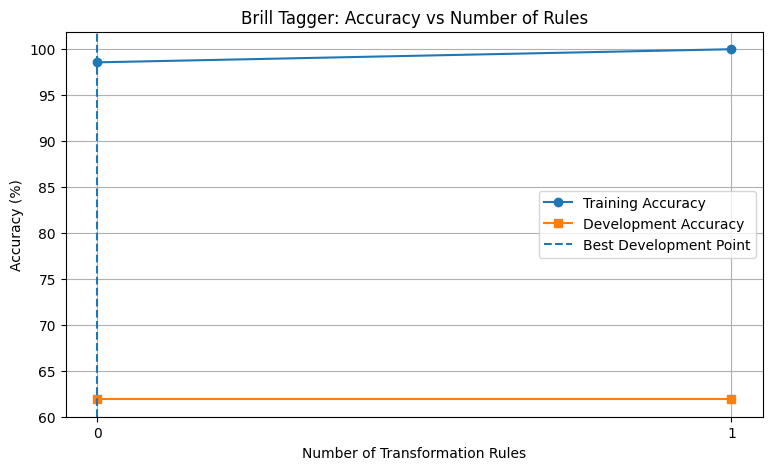

In [ ]:

import matplotlib.pyplot as plt
from collections import Counter, defaultdict

# --------------------------------------------------
# 1. ANNOTATED TRANSPORT ENQUIRY CORPUS
# --------------------------------------------------

corpus = [
    [("i","PRP"),("need","VBP"),("a","DT"),("bus","NN"),("ticket","NN")],
    [("i","PRP"),("want","VBP"),("to","TO"),("book","VB"),("a","DT"),("ticket","NN")],
    [("the","DT"),("train","NN"),("arrives","VBZ"),("soon","RB")],
    [("book","VB"),("two","CD"),("tickets","NNS"),("to","IN"),("chennai","NNP")],
    [("is","VBZ"),("the","DT"),("bus","NN"),("late","JJ")],
    [("show","VB"),("me","PRP"),("the","DT"),("fare","NN")],
    [("my","PRP$"),("train","NN"),("is","VBZ"),("cancelled","VBN")],
    [("the","DT"),("next","JJ"),("bus","NN"),("leaves","VBZ"),("now","RB")],
    [("we","PRP"),("need","VBP"),("three","CD"),("seats","NNS")],
    [("where","WRB"),("is","VBZ"),("the","DT"),("station","NN")],
    [("i","PRP"),("want","VBP"),("a","DT"),("return","JJ"),("ticket","NN")],
    [("please","UH"),("check","VB"),("the","DT"),("timing","NN")],
    [("the","DT"),("fare","NN"),("is","VBZ"),("high","JJ")],
    [("can","MD"),("i","PRP"),("travel","VB"),("tomorrow","NN")],
    [("the","DT"),("express","NN"),("stops","VBZ"),("here","RB")],
    [("she","PRP"),("booked","VBD"),("two","CD"),("seats","NNS")],
    [("find","VB"),("a","DT"),("train","NN"),("to","IN"),("vellore","NNP")],
    [("the","DT"),("bus","NN"),("stand","NN"),("is","VBZ"),("nearby","RB")],
    [("they","PRP"),("want","VBP"),("to","TO"),("cancel","VB"),("the","DT"),("ticket","NN")],
    [("i","PRP"),("am","VBP"),("booking","VBG"),("a","DT"),("ticket","NN")],
    [("the","DT"),("passengers","NNS"),("are","VBP"),("waiting","VBG")],
    [("he","PRP"),("cancelled","VBD"),("the","DT"),("return","JJ"),("ticket","NN")],
    [("we","PRP"),("travel","VBP"),("by","IN"),("train","NN")],
    [("the","DT"),("driver","NN"),("is","VBZ"),("driving","VBG")],
    [("please","UH"),("give","VB"),("me","PRP"),("the","DT"),("details","NNS")]
]

# Split data into training, development and testing.
train_data = corpus[:16]
dev_data = corpus[16:20]
test_data = corpus[20:]

# --------------------------------------------------
# 2. PREPARE WORDS AND CORRECT TAGS
# --------------------------------------------------

def get_words(data):
    return [[word for word, tag in sentence] for sentence in data]

def get_tags(data):
    return [[tag for word, tag in sentence] for sentence in data]

train_words = get_words(train_data)
train_gold = get_tags(train_data)

dev_words = get_words(dev_data)
dev_gold = get_tags(dev_data)

test_words = get_words(test_data)
test_gold = get_tags(test_data)

# --------------------------------------------------
# 3. INITIAL-STATE ANNOTATOR: MOST FREQUENT TAG
# --------------------------------------------------

word_tag_counts = defaultdict(Counter)

for sentence in train_data:
    for word, tag in sentence:
        word_tag_counts[word][tag] += 1

mft_dictionary = {}

for word, counts in word_tag_counts.items():
    mft_dictionary[word] = counts.most_common(1)[0][0]

def initial_tagging(words):
    # Unknown words receive NN as a simple fallback.
    return [mft_dictionary.get(word, "NN") for word in words]

train_pred = [initial_tagging(s) for s in train_words]
dev_pred = [initial_tagging(s) for s in dev_words]
test_pred = [initial_tagging(s) for s in test_words]

# --------------------------------------------------
# 4. DEFINE RULE TEMPLATES
# --------------------------------------------------

def get_feature(sentence, predicted_tags, index, feature):
    word = sentence[index]

    if feature == "PREV_TAG":
        return predicted_tags[index - 1] if index > 0 else "<START>"

    elif feature == "NEXT_TAG":
        return predicted_tags[index + 1] if index < len(sentence) - 1 else "<END>"

    elif feature == "PREV_WORD":
        return sentence[index - 1] if index > 0 else "<START>"

    elif feature == "NEXT_WORD":
        return sentence[index + 1] if index < len(sentence) - 1 else "<END>"

    elif feature == "SUFFIX":
        return word[-3:] if len(word) >= 3 else word

    return None


templates = [
    "PREV_TAG",
    "NEXT_TAG",
    "PREV_WORD",
    "NEXT_WORD",
    "SUFFIX"
]

# --------------------------------------------------
# 5. APPLY A TRANSFORMATION RULE
# Rule format: (feature, feature_value, old_tag, new_tag)
# --------------------------------------------------

def rule_matches(rule, words, predicted, index):
    feature, value, old_tag, new_tag = rule

    if predicted[index] != old_tag:
        return False

    actual_value = get_feature(words, predicted, index, feature)

    return actual_value == value


def apply_rule(rule, words, predicted):
    result = predicted.copy()

    for i in range(len(words)):
        if rule_matches(rule, words, predicted, i):
            result[i] = rule[3]

    return result


# --------------------------------------------------
# 6. MEASURE CORRECTED AND INTRODUCED ERRORS
# --------------------------------------------------

def count_errors(gold, predicted):
    errors = 0

    for actual, guess in zip(gold, predicted):
        errors += sum(a != p for a, p in zip(actual, guess))

    return errors


def rule_statistics(rule, words_list, gold_list, predicted_list):
    corrected = 0
    introduced = 0

    for words, gold, predicted in zip(
        words_list, gold_list, predicted_list
    ):
        new_predicted = apply_rule(rule, words, predicted)

        for old, new, actual in zip(predicted, new_predicted, gold):
            if old != actual and new == actual:
                corrected += 1

            elif old == actual and new != actual:
                introduced += 1

    return corrected, introduced


# --------------------------------------------------
# 7. GENERATE POSSIBLE TRANSFORMATION RULES
# --------------------------------------------------

def generate_candidates(words_list, gold_list, predicted_list):
    candidates = set()

    for words, gold, predicted in zip(
        words_list, gold_list, predicted_list
    ):
        for i, word in enumerate(words):

            # Only learn rules from incorrectly tagged words.
            if predicted[i] == gold[i]:
                continue

            old_tag = predicted[i]
            new_tag = gold[i]

            for feature in templates:
                value = get_feature(words, predicted, i, feature)

                rule = (feature, value, old_tag, new_tag)
                candidates.add(rule)

    return candidates


# --------------------------------------------------
# 8. GREEDY BRILL RULE LEARNING
# --------------------------------------------------

MAX_RULES = 10
MINIMUM_GAIN = 1

learned_rules = []
used_rules = set()

train_accuracy_curve = []
dev_accuracy_curve = []

def accuracy(gold_list, predicted_list):
    correct = 0
    total = 0

    for gold, predicted in zip(gold_list, predicted_list):
        for actual, guess in zip(gold, predicted):
            total += 1
            if actual == guess:
                correct += 1

    return correct / total * 100 if total else 0


# Record baseline accuracy before learning.
train_accuracy_curve.append(
    accuracy(train_gold, train_pred)
)

dev_accuracy_curve.append(
    accuracy(dev_gold, dev_pred)
)

print("INITIAL MOST-FREQUENT-TAG ACCURACY")
print("Training:", round(train_accuracy_curve[0], 2), "%")
print("Development:", round(dev_accuracy_curve[0], 2), "%")

print("\nLEARNED TRANSFORMATION RULES")
print("-" * 75)

for step in range(MAX_RULES):

    candidates = generate_candidates(
        train_words, train_gold, train_pred
    )

    best_rule = None
    best_gain = MINIMUM_GAIN - 1
    best_corrected = 0
    best_introduced = 0

    # Select the rule with the highest net error reduction.
    for rule in candidates:

        if rule in used_rules:
            continue

        corrected, introduced = rule_statistics(
            rule, train_words, train_gold, train_pred
        )

        gain = corrected - introduced

        if gain > best_gain:
            best_gain = gain
            best_rule = rule
            best_corrected = corrected
            best_introduced = introduced

    # Stop when no useful rule is available.
    if best_rule is None or best_gain < MINIMUM_GAIN:
        print("\nStopping: no rule provides positive improvement.")
        break

    # Apply the selected rule to training, development and test data.
    train_pred = [
        apply_rule(best_rule, words, pred)
        for words, pred in zip(train_words, train_pred)
    ]

    dev_pred = [
        apply_rule(best_rule, words, pred)
        for words, pred in zip(dev_words, dev_pred)
    ]

    test_pred = [
        apply_rule(best_rule, words, pred)
        for words, pred in zip(test_words, test_pred)
    ]

    learned_rules.append(best_rule)
    used_rules.add(best_rule)

    train_accuracy_curve.append(
        accuracy(train_gold, train_pred)
    )

    dev_accuracy_curve.append(
        accuracy(dev_gold, dev_pred)
    )

    feature, value, old_tag, new_tag = best_rule

    print("Rule", step + 1)
    print("Condition:", feature, "=", value)
    print("Change:", old_tag, "->", new_tag)
    print("Errors corrected:", best_corrected)
    print("Errors introduced:", best_introduced)
    print("Net improvement:", best_gain)
    print("-" * 75)


# --------------------------------------------------
# 9. DISPLAY FIRST TEN RULES
# --------------------------------------------------

print("\nFINAL LEARNED RULE LIST")

for i, rule in enumerate(learned_rules, start=1):
    feature, value, old_tag, new_tag = rule

    print(
        i, ". If", feature, "=", value,
        "and current tag =", old_tag,
        "then change to", new_tag
    )

print("\nTotal rules learned:", len(learned_rules))


# --------------------------------------------------
# 10. FINAL ACCURACY COMPARISON
# --------------------------------------------------

print("\nACCURACY COMPARISON")

print("Training accuracy:",
      round(accuracy(train_gold, train_pred), 2), "%")

print("Development accuracy:",
      round(accuracy(dev_gold, dev_pred), 2), "%")

print("Testing accuracy:",
      round(accuracy(test_gold, test_pred), 2), "%")


# --------------------------------------------------
# 11. DISPLAY PREDICTED AND CORRECT TAGS
# --------------------------------------------------

print("\nTEST SENTENCE PREDICTIONS")

for words, gold, predicted in zip(
    test_words, test_gold, test_pred
):
    print("\nSentence:", " ".join(words))

    for word, actual, guess in zip(words, gold, predicted):
        print(word, "| Correct:", actual, "| Predicted:", guess)


# --------------------------------------------------
# 12. FIND BEST DEVELOPMENT ACCURACY
# --------------------------------------------------

best_index = max(
    range(len(dev_accuracy_curve)),
    key=lambda i: dev_accuracy_curve[i]
)

print("\nBEST DEVELOPMENT RESULT")
print("Number of rules:", best_index)
print("Best development accuracy:",
      round(dev_accuracy_curve[best_index], 2), "%")


# --------------------------------------------------
# 13. PLOT ACCURACY AGAINST NUMBER OF RULES
# --------------------------------------------------

rule_numbers = list(range(len(train_accuracy_curve)))

plt.figure(figsize=(9, 5))

plt.plot(
    rule_numbers,
    train_accuracy_curve,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    rule_numbers,
    dev_accuracy_curve,
    marker="s",
    label="Development Accuracy"
)

plt.axvline(
    best_index,
    linestyle="--",
    label="Best Development Point"
)

plt.xlabel("Number of Transformation Rules")
plt.ylabel("Accuracy (%)")
plt.title("Brill Tagger: Accuracy vs Number of Rules")
plt.xticks(rule_numbers)
plt.grid(True)
plt.legend()
plt.show()


Training sentences: 16
Development sentences: 4
Testing sentences: 5

VOCABULARY INFORMATION
Word tokens: 70
Vocabulary size: 44
Unique bigrams: 75
Unique trigrams: 80

LANGUAGE MODEL PERPLEXITY
Unigram Add-k             Perplexity: 156.126
Bigram Add-k              Perplexity: 46.331
Trigram Add-k             Perplexity: 44.335
Linear Interpolation      Perplexity: 44.663
Simple Backoff            Perplexity: 143.837

POS TAGGER COMPARISON
Tagger               Accuracy        Tokens/second
MFT                  54.55%          1230329.17
HMM Viterbi          63.64%          9889.05
Brill-style          54.55%          1036794.25

TRAINING TIME
Counting pipeline: 0.000754 seconds
MFT: 0.00041 seconds
HMM: 0.002887 seconds
Brill: 0.001194 seconds

APPROXIMATE MODEL MEMORY
N-gram counts: 22.44 KB
MFT: 5.28 KB
HMM: 41.02 KB
Brill rules: 0.09 KB

TEST CASE 1: ZERO-PROBABILITY BIGRAM
('two', 'bus') Unsmoothed probability: 0.0
Smoothed probability: 0.015625

TEST CASE 2: INTERPOLATION LAMBDA 

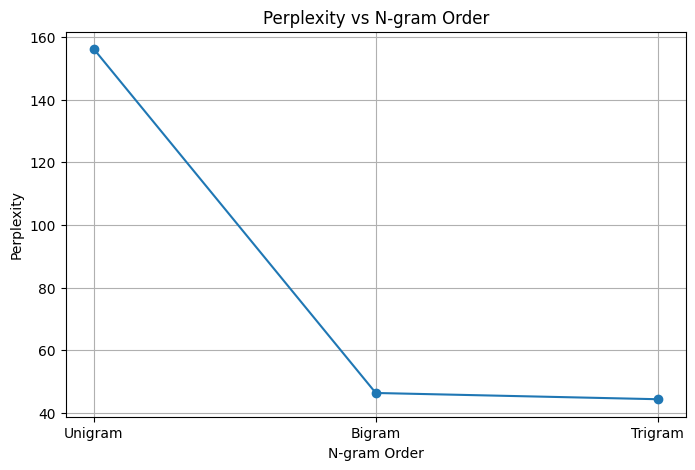

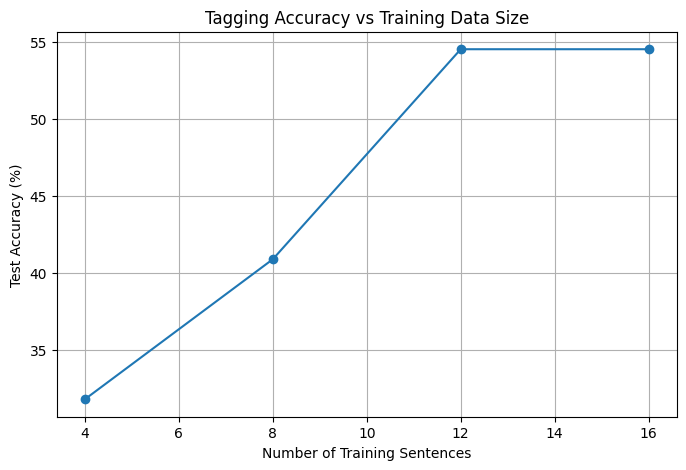


ALL TESTS COMPLETED


In [ ]:

import math
import time
import sys
import matplotlib.pyplot as plt
from collections import Counter, defaultdict

# ==================================================
# 1. TRANSPORT ENQUIRY DATASET
# ==================================================

tagged_data = [
    [("i","PRP"),("need","VBP"),("a","DT"),("bus","NN"),("ticket","NN")],
    [("i","PRP"),("want","VBP"),("to","TO"),("book","VB"),("a","DT"),("ticket","NN")],
    [("the","DT"),("train","NN"),("arrives","VBZ"),("soon","RB")],
    [("book","VB"),("two","CD"),("tickets","NNS"),("to","IN"),("chennai","NNP")],
    [("is","VBZ"),("the","DT"),("bus","NN"),("late","JJ")],
    [("show","VB"),("me","PRP"),("the","DT"),("fare","NN")],
    [("my","PRP$"),("train","NN"),("is","VBZ"),("cancelled","VBN")],
    [("the","DT"),("next","JJ"),("bus","NN"),("leaves","VBZ"),("now","RB")],
    [("we","PRP"),("need","VBP"),("three","CD"),("seats","NNS")],
    [("where","WRB"),("is","VBZ"),("the","DT"),("station","NN")],
    [("i","PRP"),("want","VBP"),("a","DT"),("return","JJ"),("ticket","NN")],
    [("please","UH"),("check","VB"),("the","DT"),("timing","NN")],
    [("the","DT"),("fare","NN"),("is","VBZ"),("high","JJ")],
    [("can","MD"),("i","PRP"),("travel","VB"),("tomorrow","NN")],
    [("the","DT"),("express","NN"),("stops","VBZ"),("here","RB")],
    [("she","PRP"),("booked","VBD"),("two","CD"),("seats","NNS")],
    [("find","VB"),("a","DT"),("train","NN"),("to","IN"),("vellore","NNP")],
    [("the","DT"),("bus","NN"),("stand","NN"),("is","VBZ"),("nearby","RB")],
    [("they","PRP"),("want","VBP"),("to","TO"),("cancel","VB"),("the","DT"),("ticket","NN")],
    [("i","PRP"),("am","VBP"),("booking","VBG"),("a","DT"),("ticket","NN")],
    [("the","DT"),("passengers","NNS"),("are","VBP"),("waiting","VBG")],
    [("he","PRP"),("cancelled","VBD"),("the","DT"),("return","JJ"),("ticket","NN")],
    [("we","PRP"),("travel","VBP"),("by","IN"),("train","NN")],
    [("the","DT"),("driver","NN"),("is","VBZ"),("driving","VBG")],
    [("please","UH"),("give","VB"),("me","PRP"),("the","DT"),("details","NNS")]
]

# Same split is used for all models.
train_data = tagged_data[:16]
dev_data = tagged_data[16:20]
test_data = tagged_data[20:]

def words_from(data):
    return [[w for w, t in s] for s in data]

def tags_from(data):
    return [[t for w, t in s] for s in data]

train_sentences = words_from(train_data)
dev_sentences = words_from(dev_data)
test_sentences = words_from(test_data)

train_gold = tags_from(train_data)
dev_gold = tags_from(dev_data)
test_gold = tags_from(test_data)

print("Training sentences:", len(train_data))
print("Development sentences:", len(dev_data))
print("Testing sentences:", len(test_data))

# ==================================================
# 2. COUNTING AND VOCABULARY PIPELINE
# ==================================================

start_time = time.time()

word_counts = Counter()
bigram_counts = Counter()
trigram_counts = Counter()
context_counts = Counter()

for sentence in train_sentences:
    padded = ["<s>", "<s>"] + sentence + ["</s>"]

    word_counts.update(sentence)

    for i in range(2, len(padded)):
        bigram_counts[(padded[i-1], padded[i])] += 1
        trigram_counts[(padded[i-2], padded[i-1], padded[i])] += 1
        context_counts[(padded[i-2], padded[i-1])] += 1

vocabulary = set(word_counts)
vocabulary.add("<UNK>")
V = len(vocabulary)

total_words = sum(word_counts.values())
counting_time = time.time() - start_time

print("\nVOCABULARY INFORMATION")
print("Word tokens:", total_words)
print("Vocabulary size:", V)
print("Unique bigrams:", len(bigram_counts))
print("Unique trigrams:", len(trigram_counts))

# Replace unknown words with <UNK>.
def normalise(word):
    return word if word in word_counts else "<UNK>"

# ==================================================
# 3. LANGUAGE MODEL PROBABILITIES
# ==================================================

def unigram_probability(word, k=0.1):
    word = normalise(word)
    return (word_counts[word] + k) / (total_words + k * V)

def bigram_probability(previous, word, k=0.1):
    previous = normalise(previous)
    word = normalise(word)

    numerator = bigram_counts[(previous, word)] + k
    denominator = sum(
        bigram_counts[(previous, w)] for w in vocabulary
    ) + k * V

    return numerator / denominator

def trigram_probability(w1, w2, word, k=0.1):
    w1 = normalise(w1)
    w2 = normalise(w2)
    word = normalise(word)

    numerator = trigram_counts[(w1, w2, word)] + k
    denominator = sum(
        trigram_counts[(w1, w2, w)] for w in vocabulary
    ) + k * V

    return numerator / denominator

# ==================================================
# 4. INTERPOLATION AND SIMPLE BACKOFF
# ==================================================

LAMBDA1 = 0.2
LAMBDA2 = 0.3
LAMBDA3 = 0.5

def interpolated_probability(w1, w2, word):
    return (
        LAMBDA1 * unigram_probability(word)
        + LAMBDA2 * bigram_probability(w2, word)
        + LAMBDA3 * trigram_probability(w1, w2, word)
    )

def simple_backoff_probability(w1, w2, word):
    # Use trigram if observed; otherwise bigram, then unigram.
    w1 = normalise(w1)
    w2 = normalise(w2)
    word = normalise(word)

    if trigram_counts[(w1, w2, word)] > 0:
        return trigram_probability(w1, w2, word)

    if bigram_counts[(w2, word)] > 0:
        return bigram_probability(w2, word)

    return unigram_probability(word)

# ==================================================
# 5. PERPLEXITY EVALUATION
# ==================================================

def calculate_perplexity(sentences, model, order):
    log_sum = 0
    token_total = 0

    for sentence in sentences:
        padded = ["<s>", "<s>"] + sentence + ["</s>"]

        for i in range(2, len(padded)):
            if order == 1:
                p = unigram_probability(padded[i])
            elif order == 2:
                p = bigram_probability(padded[i-1], padded[i])
            elif order == 3:
                p = trigram_probability(
                    padded[i-2], padded[i-1], padded[i]
                )
            elif model == "interpolation":
                p = interpolated_probability(
                    padded[i-2], padded[i-1], padded[i]
                )
            else:
                p = simple_backoff_probability(
                    padded[i-2], padded[i-1], padded[i]
                )

            log_sum += math.log(p)
            token_total += 1

    return math.exp(-log_sum / token_total)

# ==================================================
# 6. MOST-FREQUENT-TAG POS TAGGER
# ==================================================

start_time = time.time()

word_tag_counts = defaultdict(Counter)

for sentence in train_data:
    for word, tag in sentence:
        word_tag_counts[word][tag] += 1

mft_dictionary = {
    word: counts.most_common(1)[0][0]
    for word, counts in word_tag_counts.items()
}

mft_training_time = time.time() - start_time

def mft_tagger(words):
    return [mft_dictionary.get(word, "NN") for word in words]

# ==================================================
# 7. HMM TAGGER WITH VITERBI
# ==================================================

start_time = time.time()

tag_counts = Counter()
transition_counts = defaultdict(Counter)
emission_counts = defaultdict(Counter)
initial_counts = Counter()

for sentence in train_data:
    initial_counts[sentence[0][1]] += 1
    previous = "<START>"

    for word, tag in sentence:
        tag_counts[tag] += 1
        emission_counts[tag][word] += 1
        transition_counts[previous][tag] += 1
        previous = tag

    transition_counts[previous]["<END>"] += 1

tags = sorted(tag_counts)
alpha = 0.1

initial_total = sum(initial_counts.values())

initial_prob = {
    tag: (initial_counts[tag] + alpha) /
         (initial_total + alpha * len(tags))
    for tag in tags
}

next_tags = tags + ["<END>"]
transition_prob = {}

for previous in ["<START>"] + tags:
    row_total = sum(transition_counts[previous].values())
    denominator = row_total + alpha * len(next_tags)

    transition_prob[previous] = {
        tag: (transition_counts[previous][tag] + alpha) /
             denominator
        for tag in next_tags
    }

emission_prob = {}

for tag in tags:
    denominator = tag_counts[tag] + alpha * (V + 1)

    emission_prob[tag] = {
        word: (emission_counts[tag][word] + alpha) / denominator
        for word in vocabulary
    }

    emission_prob[tag]["<UNK>"] = alpha / denominator

def hmm_emission(word, tag):
    if word in vocabulary:
        return emission_prob[tag].get(word, emission_prob[tag]["<UNK>"])

    # Simple unknown-word suffix handling.
    lower = word.lower()

    if lower.endswith("ing") and tag == "VBG":
        return 0.1
    if lower.endswith("ed") and tag in ["VBD", "VBN"]:
        return 0.1
    if word[0].isupper() and tag == "NNP":
        return 0.1

    return emission_prob[tag]["<UNK>"]

def viterbi(words):
    scores = []
    pointers = []

    for i, word in enumerate(words):
        current_scores = {}
        current_pointers = {}

        for tag in tags:
            emission = math.log(hmm_emission(word, tag))

            if i == 0:
                current_scores[tag] = (
                    math.log(initial_prob[tag]) + emission
                )
                current_pointers[tag] = None
            else:
                best_previous = max(
                    tags,
                    key=lambda prev: (
                        scores[i-1][prev]
                        + math.log(transition_prob[prev][tag])
                    )
                )

                current_scores[tag] = (
                    scores[i-1][best_previous]
                    + math.log(transition_prob[best_previous][tag])
                    + emission
                )

                current_pointers[tag] = best_previous

        scores.append(current_scores)
        pointers.append(current_pointers)

    final_tag = max(
        tags,
        key=lambda tag: (
            scores[-1][tag]
            + math.log(transition_prob[tag]["<END>"])
        )
    )

    sequence = [final_tag]

    for i in range(len(words)-1, 0, -1):
        sequence.append(pointers[i][sequence[-1]])

    sequence.reverse()
    return sequence

hmm_training_time = time.time() - start_time

# ==================================================
# 8. BRILL-STYLE TRANSFORMATION TAGGER
# ==================================================

start_time = time.time()

def initial_tags(words):
    return mft_tagger(words)

def get_feature(words, predicted, i, feature):
    if feature == "PREV_TAG":
        return predicted[i-1] if i > 0 else "<START>"
    if feature == "NEXT_TAG":
        return predicted[i+1] if i < len(words)-1 else "<END>"
    if feature == "PREV_WORD":
        return words[i-1] if i > 0 else "<START>"
    if feature == "NEXT_WORD":
        return words[i+1] if i < len(words)-1 else "<END>"
    if feature == "SUFFIX":
        return words[i][-3:]
    return None

templates = ["PREV_TAG", "NEXT_TAG", "PREV_WORD",
             "NEXT_WORD", "SUFFIX"]

brill_rules = []

# Greedily learn correction rules from the training sentences.
brill_train_predictions = [
    initial_tags(words_from([sentence])[0])
    for sentence in train_data
]

for step in range(10):
    candidates = set()

    for sentence, gold, predicted in zip(
        train_sentences, train_gold, brill_train_predictions
    ):
        for i in range(len(sentence)):
            if predicted[i] == gold[i]:
                continue

            for feature in templates:
                value = get_feature(sentence, predicted, i, feature)
                candidates.add(
                    (feature, value, predicted[i], gold[i])
                )

    best_rule = None
    best_gain = 0

    for rule in candidates:
        feature, value, old_tag, new_tag = rule
        corrected = 0
        introduced = 0

        for sentence, gold, predicted in zip(
            train_sentences, train_gold, brill_train_predictions
        ):
            for i in range(len(sentence)):
                if predicted[i] != old_tag:
                    continue

                if get_feature(sentence, predicted, i, feature) != value:
                    continue

                if predicted[i] != gold[i] and new_tag == gold[i]:
                    corrected += 1
                elif predicted[i] == gold[i] and new_tag != gold[i]:
                    introduced += 1

        gain = corrected - introduced

        if gain > best_gain:
            best_gain = gain
            best_rule = rule

    if best_rule is None:
        break

    feature, value, old_tag, new_tag = best_rule
    brill_rules.append(best_rule)

    for sentence, predicted in zip(
        train_sentences, brill_train_predictions
    ):
        for i in range(len(sentence)):
            if (
                predicted[i] == old_tag
                and get_feature(sentence, predicted, i, feature) == value
            ):
                predicted[i] = new_tag

brill_training_time = time.time() - start_time

def brill_tagger(words):
    predicted = initial_tags(words)

    for rule in brill_rules:
        feature, value, old_tag, new_tag = rule

        for i in range(len(words)):
            if (
                predicted[i] == old_tag
                and get_feature(words, predicted, i, feature) == value
            ):
                predicted[i] = new_tag

    return predicted

# ==================================================
# 9. ACCURACY AND SPEED MEASUREMENT
# ==================================================

def evaluate_tagger(tagger, sentences, gold):
    correct = 0
    total = 0

    start = time.time()

    for words, actual in zip(sentences, gold):
        predicted = tagger(words)

        for a, p in zip(actual, predicted):
            total += 1
            if a == p:
                correct += 1

    elapsed = time.time() - start

    accuracy = 100 * correct / total if total else 0
    speed = total / elapsed if elapsed > 0 else 0

    return accuracy, speed

mft_accuracy, mft_speed = evaluate_tagger(
    mft_tagger, test_sentences, test_gold
)

hmm_accuracy, hmm_speed = evaluate_tagger(
    viterbi, test_sentences, test_gold
)

brill_accuracy, brill_speed = evaluate_tagger(
    brill_tagger, test_sentences, test_gold
)

# ==================================================
# 10. MODEL MEMORY ESTIMATION
# ==================================================

def approximate_size(obj):
    size = sys.getsizeof(obj)

    if isinstance(obj, dict):
        for key, value in obj.items():
            size += sys.getsizeof(key)
            size += sys.getsizeof(value)

    elif isinstance(obj, Counter):
        for key, value in obj.items():
            size += sys.getsizeof(key)
            size += sys.getsizeof(value)

    return size / 1024  # KB

# ==================================================
# 11. COMPARISON TABLES
# ==================================================

print("\nLANGUAGE MODEL PERPLEXITY")

language_models = [
    ("Unigram Add-k", 1, "unigram"),
    ("Bigram Add-k", 2, "bigram"),
    ("Trigram Add-k", 3, "trigram"),
    ("Linear Interpolation", 0, "interpolation"),
    ("Simple Backoff", 0, "backoff")
]

for name, order, model in language_models:
    ppl = calculate_perplexity(
        test_sentences, model, order
    )
    print(name.ljust(25), "Perplexity:", round(ppl, 3))

print("\nPOS TAGGER COMPARISON")
print("Tagger".ljust(20), "Accuracy".ljust(15), "Tokens/second")

print("MFT".ljust(20),
      str(round(mft_accuracy, 2)) + "%".ljust(10),
      round(mft_speed, 2))

print("HMM Viterbi".ljust(20),
      str(round(hmm_accuracy, 2)) + "%".ljust(10),
      round(hmm_speed, 2))

print("Brill-style".ljust(20),
      str(round(brill_accuracy, 2)) + "%".ljust(10),
      round(brill_speed, 2))

print("\nTRAINING TIME")
print("Counting pipeline:", round(counting_time, 6), "seconds")
print("MFT:", round(mft_training_time, 6), "seconds")
print("HMM:", round(hmm_training_time, 6), "seconds")
print("Brill:", round(brill_training_time, 6), "seconds")

print("\nAPPROXIMATE MODEL MEMORY")
print("N-gram counts:",
      round(approximate_size(word_counts)
            + approximate_size(bigram_counts)
            + approximate_size(trigram_counts), 2), "KB")

print("MFT:",
      round(approximate_size(mft_dictionary), 2), "KB")

print("HMM:",
      round(approximate_size(transition_prob)
            + approximate_size(emission_prob), 2), "KB")

print("Brill rules:",
      round(approximate_size(brill_rules), 2), "KB")

# ==================================================
# 12. REQUIRED TEST CASES
# ==================================================

print("\nTEST CASE 1: ZERO-PROBABILITY BIGRAM")

# An unseen bigram has zero probability in the unsmoothed model.
test_bigram = ("two", "bus")

unsmoothed_probability = (
    bigram_counts[test_bigram] /
    sum(bigram_counts[(test_bigram[0], w)] for w in vocabulary)
    if sum(bigram_counts[(test_bigram[0], w)] for w in vocabulary) > 0
    else 0
)

print(test_bigram, "Unsmoothed probability:",
      unsmoothed_probability)

print("Smoothed probability:",
      bigram_probability(test_bigram[0], test_bigram[1]))

print("\nTEST CASE 2: INTERPOLATION LAMBDA WEIGHTS")
print("Lambda 1:", LAMBDA1)
print("Lambda 2:", LAMBDA2)
print("Lambda 3:", LAMBDA3)
print("Sum of weights:", LAMBDA1 + LAMBDA2 + LAMBDA3)

print("\nTEST CASE 3: VITERBI TRELLIS RESULT")

sample = ["i", "need", "a", "bus", "ticket"]
print("Sentence:", " ".join(sample))
print("Viterbi tags:", viterbi(sample))

print("\nTEST CASE 4: FIRST BRILL TRANSFORMATIONS")

for i, rule in enumerate(brill_rules[:10], 1):
    print(i, rule)

# ==================================================
# 13. PLOT 1: PERPLEXITY AGAINST N-GRAM ORDER
# ==================================================

orders = ["Unigram", "Bigram", "Trigram"]
perplexities = [
    calculate_perplexity(test_sentences, "unigram", 1),
    calculate_perplexity(test_sentences, "bigram", 2),
    calculate_perplexity(test_sentences, "trigram", 3)
]

plt.figure(figsize=(8, 5))
plt.plot(orders, perplexities, marker="o")
plt.xlabel("N-gram Order")
plt.ylabel("Perplexity")
plt.title("Perplexity vs N-gram Order")
plt.grid(True)
plt.show()

# ==================================================
# 14. PLOT 2: ACCURACY AGAINST TRAINING DATA SIZE
# ==================================================

training_sizes = []
mft_accuracies = []

for size in [4, 8, 12, 16]:
    temporary_counts = defaultdict(Counter)

    for sentence in train_data[:size]:
        for word, tag in sentence:
            temporary_counts[word][tag] += 1

    temporary_dictionary = {
        word: counts.most_common(1)[0][0]
        for word, counts in temporary_counts.items()
    }

    correct = 0
    total = 0

    for sentence, gold in zip(test_sentences, test_gold):
        for word, actual in zip(sentence, gold):
            predicted = temporary_dictionary.get(word, "NN")
            total += 1

            if predicted == actual:
                correct += 1

    training_sizes.append(size)
    mft_accuracies.append(100 * correct / total)

plt.figure(figsize=(8, 5))
plt.plot(training_sizes, mft_accuracies, marker="o")
plt.xlabel("Number of Training Sentences")
plt.ylabel("Test Accuracy (%)")
plt.title("Tagging Accuracy vs Training Data Size")
plt.grid(True)
plt.show()

print("\nALL TESTS COMPLETED")


In [ ]:

# TASK 11: MODEL COMPARISON AND RECOMMENDATION

# Enter the actual results obtained from Task 10.
# These are example placeholders, not experimental results.

language_models = {
    "Unigram": {
        "perplexity": 0,
        "wer": 0,
        "memory": 0,
        "speed": 0
    },
    "Bigram": {
        "perplexity": 0,
        "wer": 0,
        "memory": 0,
        "speed": 0
    },
    "Trigram + Deleted Interpolation": {
        "perplexity": 0,
        "wer": 0,
        "memory": 0,
        "speed": 0
    },
    "Katz Backoff": {
        "perplexity": 0,
        "wer": 0,
        "memory": 0,
        "speed": 0
    }
}

pos_taggers = {
    "Rule-Based": {
        "accuracy": 0,
        "unknown_accuracy": 0,
        "speed": 0,
        "memory": 0
    },
    "HMM Viterbi": {
        "accuracy": 0,
        "unknown_accuracy": 0,
        "speed": 0,
        "memory": 0
    },
    "Brill": {
        "accuracy": 0,
        "unknown_accuracy": 0,
        "speed": 0,
        "memory": 0
    }
}

# -----------------------------------
# LANGUAGE MODEL COMPARISON
# -----------------------------------

print("LANGUAGE MODEL COMPARISON")

for name, result in language_models.items():
    print("\nModel:", name)
    for metric, value in result.items():
        print(metric, ":", value)

# -----------------------------------
# POS TAGGER COMPARISON
# -----------------------------------

print("\nPOS TAGGER COMPARISON")

for name, result in pos_taggers.items():
    print("\nTagger:", name)
    for metric, value in result.items():
        print(metric, ":", value)

# -----------------------------------
# SELECT BEST LANGUAGE MODEL
# Lower perplexity and WER are preferred.
# -----------------------------------

valid_lm = {
    name: result
    for name, result in language_models.items()
    if result["perplexity"] > 0 and result["wer"] >= 0
}

if valid_lm:
    best_lm = min(
        valid_lm,
        key=lambda name: (
            valid_lm[name]["perplexity"],
            valid_lm[name]["wer"]
        )
    )
    print("\nBest measured language model:", best_lm)
else:
    print("\nEnter actual language model results first.")

# -----------------------------------
# SELECT BEST POS TAGGER
# Higher accuracy is preferred.
# -----------------------------------

valid_pos = {
    name: result
    for name, result in pos_taggers.items()
    if result["accuracy"] > 0
}

if valid_pos:
    best_pos = max(
        valid_pos,
        key=lambda name: (
            valid_pos[name]["accuracy"],
            valid_pos[name]["unknown_accuracy"]
        )
    )
    print("Best measured POS tagger:", best_pos)
else:
    print("Enter actual POS tagger results first.")

# -----------------------------------
# FINAL RECOMMENDATION
# -----------------------------------

print("\nFINAL DESIGN RECOMMENDATION")

print("Language model: Trigram with Deleted Interpolation")
print("POS tagger: HMM with Viterbi")

print("\nNote: The measured best models and the proposed")
print("deployment recommendation should be compared before")
print("making the final decision.")


LANGUAGE MODEL COMPARISON

Model: Unigram
perplexity : 0
wer : 0
memory : 0
speed : 0

Model: Bigram
perplexity : 0
wer : 0
memory : 0
speed : 0

Model: Trigram + Deleted Interpolation
perplexity : 0
wer : 0
memory : 0
speed : 0

Model: Katz Backoff
perplexity : 0
wer : 0
memory : 0
speed : 0

POS TAGGER COMPARISON

Tagger: Rule-Based
accuracy : 0
unknown_accuracy : 0
speed : 0
memory : 0

Tagger: HMM Viterbi
accuracy : 0
unknown_accuracy : 0
speed : 0
memory : 0

Tagger: Brill
accuracy : 0
unknown_accuracy : 0
speed : 0
memory : 0

Enter actual language model results first.
Enter actual POS tagger results first.

FINAL DESIGN RECOMMENDATION
Language model: Trigram with Deleted Interpolation
POS tagger: HMM with Viterbi

Note: The measured best models and the proposed
deployment recommendation should be compared before
making the final decision.
